# 1 PREPARACION

In [1]:
import warnings

warnings.filterwarnings("ignore", category=UserWarning)

In [2]:
!mv /content/drive /content/drive_old_$(date +%s)
from google.colab import drive
drive.mount('/content/drive')


mv: cannot move '/content/drive' to '/content/drive_old_1795227428': Device or resource busy
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
!mkdir -p "/content/drive/MyDrive/NTT/datos"
!unzip -o -q "/content/drive/MyDrive/NTT/datos_conecta.zip" -d "/content/drive/MyDrive/NTT/datos"
!ls -la "/content/drive/MyDrive/NTT/datos"

total 24979
drwx------ 3 root root     4096 Nov 21 02:17 .
drwx------ 3 root root     4096 Nov 19 16:41 ..
-rw------- 1 root root     9588 Nov 21 01:36 app.py
-rw------- 1 root root  3293184 Nov 19 09:53 conecta.db
-rw------- 1 root root   175974 Nov 21 00:16 dashboard_clientes.csv
-rw------- 1 root root    13052 Nov 21 01:11 dash.ipynb
-rw------- 1 root root 18390383 Nov 19 09:53 eventos.jsonl
-rw------- 1 root root  1913072 Nov 19 09:53 eventos.jsonl.gz
-rw------- 1 root root    45019 Nov 21 01:36 predicciones.csv
-rw------- 1 root root     3549 Nov 21 00:16 shap_importancia.csv
drwx------ 2 root root     4096 Nov 21 01:36 sweetviz_reports
-rw------- 1 root root  1720953 Nov 19 09:53 tickets.jsonl


In [4]:
!gunzip -fk "/content/drive/MyDrive/NTT/datos/eventos.jsonl.gz"
!ls -lh "/content/drive/MyDrive/NTT/datos/"

total 25M
-rw------- 1 root root 9.4K Nov 21 01:36 app.py
-rw------- 1 root root 3.2M Nov 19 09:53 conecta.db
-rw------- 1 root root 172K Nov 21 00:16 dashboard_clientes.csv
-rw------- 1 root root  13K Nov 21 01:11 dash.ipynb
-rw------- 1 root root  18M Nov 19 09:53 eventos.jsonl
-rw------- 1 root root 1.9M Nov 19 09:53 eventos.jsonl.gz
-rw------- 1 root root  44K Nov 21 01:36 predicciones.csv
-rw------- 1 root root 3.5K Nov 21 00:16 shap_importancia.csv
drwx------ 2 root root 4.0K Nov 21 01:36 sweetviz_reports
-rw------- 1 root root 1.7M Nov 19 09:53 tickets.jsonl


In [5]:
!pip install -q sweetviz
!pip install mlflow -q
!pip install -q mlflow

In [6]:
import sqlite3
import pandas as pd
import json, gzip
import os
import json
import tempfile
import numpy as np
import pandas as pd
import mlflow
import mlflow.sklearn
import shap


# Validacion carga datos - CNX

## BD



In [7]:
con = sqlite3.connect('/content/drive/MyDrive/NTT/datos/conecta.db')
pd.read_sql("SELECT name FROM sqlite_master WHERE type='table'", con)

,name
0,clientes
1,suscripciones
2,facturas
3,etiquetas_entrenamiento
4,clientes_a_puntuar


##  No estructurada (JSON)

In [8]:
with open('/content/drive/MyDrive/NTT/datos/tickets.jsonl', encoding='utf-8') as f:
    tickets = [json.loads(linea) for linea in f]
print(len(tickets), 'tickets')
tickets[10]

4526 tickets


{'ticket_id': 'TK-0000272',
 'customer': 'CL-010163',
 'created_at': '2023-03-19T20:39:00Z',
 'channel': 'email',
 'category': 'cambio_plan',
 'text': '¿Cómo hago para pasar a un plan más económico?',
 'status': 'closed',
 'resolved_at': '2023-04-28T00:39:00Z',
 'csat': 3}

In [9]:
with gzip.open('/content/drive/MyDrive/NTT/datos/eventos.jsonl.gz', 'rt', encoding='utf-8') as f:
    eventos = [json.loads(linea) for linea in f]
print(len(eventos), 'eventos')
eventos[8]

107812 eventos


{'event_id': 'e00064139',
 'cliente_id': 11808,
 'ts': '2025-08-09T23:37:14Z',
 'tipo': 'uso_funcionalidad',
 'plataforma': 'ios',
 'version_app': '5.3.3',
 'duracion_seg': 98,
 'funcionalidad': 'favoritos'}

# EDA
Para el analisis exploratorio me apoye en la libreria sweetviz. En la ruta "/content/drive/MyDrive/NTT/datos/sweetviz_reports/" contiene toda la informacion de la completitud de las tablas e información no estructurada.

In [10]:
df_cliente = pd.read_sql ( "select * from clientes ", con)
df_suscripciones = pd.read_sql ( "select * from suscripciones ", con)
df_facturas = pd.read_sql ( "select * from facturas ", con)
df_etiquetas_entrenamiento = pd.read_sql ( "select * from etiquetas_entrenamiento ", con)
df_clientes_a_puntuar = pd.read_sql ( "select * from clientes_a_puntuar ", con)


In [11]:
dataframes = {
    'df_cliente': df_cliente,
    'df_suscripciones': df_suscripciones,
    'df_facturas': df_facturas,
    'df_etiquetas_entrenamiento': df_etiquetas_entrenamiento,
    'df_clientes_a_puntuar': df_clientes_a_puntuar
}

for nombre, df in dataframes.items():
    print(f"El DataFrame '{nombre}' tiene {df.shape[0]} filas y {df.shape[1]} columnas.")

El DataFrame 'df_cliente' tiene 3000 filas y 10 columnas.
El DataFrame 'df_suscripciones' tiene 3368 filas y 6 columnas.
El DataFrame 'df_facturas' tiene 34935 filas y 9 columnas.
El DataFrame 'df_etiquetas_entrenamiento' tiene 4879 filas y 3 columnas.
El DataFrame 'df_clientes_a_puntuar' tiene 1611 filas y 1 columnas.


In [12]:
for nombre, df in dataframes.items():
    print(f"=== Muestra de {nombre} (3 primeros registros) ===")
    display(df.head(3))
    print("\n" + "="*60 + "\n")

=== Muestra de df_cliente (3 primeros registros) ===


,cliente_id,fecha_alta,segmento,ciudad,edad,canal_adquisicion,plataforma_principal,estado_actual,contactado_por_retencion,fecha_contacto_retencion
0,10000,2024-05-13,Personal,BOGOTA,36,referido,ios,inactivo,0,None
1,10001,2024-03-28,Personal,Bogotá,29,web,android,activo,0,None
2,10002,2025-03-19,Pyme,Bogotá,40,app,ios,inactivo,1,2025-03-10




=== Muestra de df_suscripciones (3 primeros registros) ===


,suscripcion_id,cliente_id,plan,fecha_inicio,fecha_fin,motivo_cancelacion
0,100000,10000,Premium,2024-05-13,2024-10-10,problemas_tecnicos
1,100001,10001,Basico,2024-03-28,None,None
2,100002,10002,Estandar,2025-03-19,2025-03-24,calidad_servicio




=== Muestra de df_facturas (3 primeros registros) ===


,factura_id,cliente_id,suscripcion_id,periodo,monto,fecha_vencimiento,fecha_pago,metodo_pago,fecha_carga
0,5000000,10000,100000,2024-05,49900,2024-05-15,2024-05-13,tarjeta,2024-05-02 02:00:00
1,5000001,10000,100000,2024-06,49900,2024-06-15,2024-06-09,pse,2024-06-02 02:00:00
2,5000002,10000,100000,2024-07,49900,2024-07-15,2024-07-11,pse,2024-07-02 02:00:00




=== Muestra de df_etiquetas_entrenamiento (3 primeros registros) ===


,cliente_id,fecha_corte,churn_90d
0,10001,2025-03-31,0
1,10007,2025-03-31,0
2,10012,2025-03-31,0




=== Muestra de df_clientes_a_puntuar (3 primeros registros) ===


,cliente_id
0,10001
1,10003
2,10004


In [13]:
for nombre, df in dataframes.items():
    print(f"=== Descripción estadística de {nombre} ===")
    display(df.describe(include='all'))
    print("\n" + "="*60 + "\n")

=== Descripción estadística de df_cliente ===


,cliente_id,fecha_alta,segmento,ciudad,edad,canal_adquisicion,plataforma_principal,estado_actual,contactado_por_retencion,fecha_contacto_retencion
count,3000.000000,3000,3000,3000,3000.000000,3000,3000,3000,3000.000000,892
unique,NaN,909,2,17,NaN,5,3,2,NaN,501
top,NaN,2025-10-28,Personal,BOGOTA,NaN,web,android,activo,NaN,2025-08-15
freq,NaN,11,2352,310,NaN,1049,1653,1611,NaN,9
mean,11499.500000,NaN,NaN,NaN,48.728333,NaN,NaN,NaN,0.297333,NaN
std,866.169729,NaN,NaN,NaN,101.046498,NaN,NaN,NaN,0.457161,NaN
min,10000.000000,NaN,NaN,NaN,0.000000,NaN,NaN,NaN,0.000000,NaN
25%,10749.750000,NaN,NaN,NaN,30.000000,NaN,NaN,NaN,0.000000,NaN
50%,11499.500000,NaN,NaN,NaN,38.000000,NaN,NaN,NaN,0.000000,NaN
75%,12249.250000,NaN,NaN,NaN,46.000000,NaN,NaN,NaN,1.000000,NaN




=== Descripción estadística de df_suscripciones ===


,suscripcion_id,cliente_id,plan,fecha_inicio,fecha_fin,motivo_cancelacion
count,3368.000000,3368.000000,3368,3368,1757,1757
unique,NaN,NaN,4,951,713,8
top,NaN,NaN,Basico,2025-10-28,2025-10-17,cambio_plan
freq,NaN,NaN,1109,14,11,368
mean,101712.215855,11497.398753,NaN,NaN,NaN,NaN
std,990.195738,866.587808,NaN,NaN,NaN,NaN
min,100000.000000,10000.000000,NaN,NaN,NaN,NaN
25%,100853.750000,10748.750000,NaN,NaN,NaN,NaN
50%,101711.500000,11493.000000,NaN,NaN,NaN,NaN
75%,102567.250000,12252.250000,NaN,NaN,NaN,NaN




=== Descripción estadística de df_facturas ===


,factura_id,cliente_id,suscripcion_id,periodo,monto,fecha_vencimiento,fecha_pago,metodo_pago,fecha_carga
count,3.493500e+04,34935.000000,34935.000000,34935,34935.000000,34935,33556,34935,34935
unique,NaN,NaN,NaN,36,NaN,36,963,4,71
top,NaN,NaN,NaN,2025-10,NaN,2025-10-15,2025-09-12,tarjeta,2025-10-02 02:00:00
freq,NaN,NaN,NaN,1983,NaN,1983,197,13954,1951
mean,5.019529e+06,11516.270645,101733.758151,NaN,37369.987119,NaN,NaN,NaN,NaN
std,1.126434e+04,868.849428,992.712323,NaN,13838.380720,NaN,NaN,NaN,NaN
min,5.000000e+06,10000.000000,100000.000000,NaN,19900.000000,NaN,NaN,NaN,NaN
25%,5.009792e+06,10767.000000,100880.000000,NaN,23900.000000,NaN,NaN,NaN,NaN
50%,5.019493e+06,11514.000000,101736.000000,NaN,34900.000000,NaN,NaN,NaN,NaN
75%,5.029290e+06,12288.000000,102607.000000,NaN,49900.000000,NaN,NaN,NaN,NaN




=== Descripción estadística de df_etiquetas_entrenamiento ===


,cliente_id,fecha_corte,churn_90d
count,4879.000000,4879,4879.000000
unique,NaN,3,NaN
top,NaN,2025-09-30,NaN
freq,NaN,1795,NaN
mean,11512.968641,NaN,0.129125
std,874.183012,NaN,0.335372
min,10001.000000,NaN,0.000000
25%,10752.500000,NaN,0.000000
50%,11521.000000,NaN,0.000000
75%,12293.000000,NaN,0.000000




=== Descripción estadística de df_clientes_a_puntuar ===


,cliente_id
count,1611.000000
mean,11512.535692
std,870.996503
min,10001.000000
25%,10753.000000
50%,11533.000000
75%,12284.500000
max,12998.000000


In [14]:
for nombre, df in dataframes.items():
    # Identificar columnas donde todos los valores son nulos (NaN/None)
    columnas_vacias = df.columns[df.isna().all()].tolist()

    if columnas_vacias:
        print(f"El DataFrame '{nombre}' tiene las siguientes columnas vacías: {columnas_vacias}")
    else:
        print(f"El DataFrame '{nombre}' no tiene ninguna columna completamente vacía.")

El DataFrame 'df_cliente' no tiene ninguna columna completamente vacía.
El DataFrame 'df_suscripciones' no tiene ninguna columna completamente vacía.
El DataFrame 'df_facturas' no tiene ninguna columna completamente vacía.
El DataFrame 'df_etiquetas_entrenamiento' no tiene ninguna columna completamente vacía.
El DataFrame 'df_clientes_a_puntuar' no tiene ninguna columna completamente vacía.


In [15]:
df_tickets = pd.DataFrame(tickets)
df_eventos = pd.DataFrame(eventos)

df_tickets.head(2)


,ticket_id,customer,created_at,channel,category,text,status,resolved_at,csat,id,cliente,fecha,canal,tipo,mensajes,estado,satisfaccion
0,TK-0000777,CL-010453,2023-02-18T12:20:00Z,chat,cambio_clave,Olvidé mi clave y el enlace de recuperación no...,closed,2023-03-28T19:20:00Z,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,TK-0003069,CL-011718,2023-02-19T01:55:00Z,telefono,cancelar,Quiero cancelar ya. No me interesa ninguna ofe...,closed,2023-02-21T07:55:00Z,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [16]:
df_eventos.head(2)


,event_id,cliente_id,ts,tipo,plataforma,version_app,duracion_seg,funcionalidad,codigo_error
0,e00066719,11878,2025-11-24T20:09:56Z,login,android,5.3.3,NaN,NaN,NaN
1,e00037529,11064,2025-11-28T12:51:55Z,login,ios,5.3.3,NaN,NaN,NaN


In [17]:
df_timeouts = df_eventos[df_eventos['codigo_error'] == 'CRASH_ON_START']
df_timeouts.head(2)

,event_id,cliente_id,ts,tipo,plataforma,version_app,duracion_seg,funcionalidad,codigo_error
7,e00021688,10612,2025-09-06T07:34:46Z,error_app,android,5.4.0,NaN,NaN,CRASH_ON_START
16,e00025610,10715,2025-12-01T13:42:00Z,error_app,android,5.4.0,NaN,NaN,CRASH_ON_START


In [18]:
def construir_dataset_base(df_base: pd.DataFrame, clientes: pd.DataFrame,
                           suscripciones: pd.DataFrame, facturas: pd.DataFrame,
                           tickets: pd.DataFrame, eventos: pd.DataFrame) -> pd.DataFrame:
    df = df_base.copy()
    df["fecha_corte"] = pd.to_datetime(df["fecha_corte"])

    # 1. Features de clientes (antigüedad relativa al corte)
    cli = clientes.copy()
    cli["fecha_alta"] = pd.to_datetime(cli["fecha_alta"])
    df = df.merge(cli, on="cliente_id", how="left")
    df["antiguedad_dias"] = (df["fecha_corte"] - df["fecha_alta"]).dt.days

    # 2. Ejemplo de agregación temporal para una tabla con fecha (repetir por fuente)
    # Filtra estrictamente <= fecha_corte y resume por cliente_id + fecha_corte
    ev = eventos.copy()
    ev["fecha_evento"] = pd.to_datetime(ev["timestamp"]).dt.normalize()

    ev_cortes = (
        df[["cliente_id", "fecha_corte"]]
        .drop_duplicates()
        .merge(ev, on="cliente_id", how="inner")
    )
    ev_cortes = ev_cortes[
        (ev_cortes["fecha_evento"] <= ev_cortes["fecha_corte"]) &
        (ev_cortes["fecha_evento"] > ev_cortes["fecha_corte"] - pd.Timedelta(days=30))
    ]

    ev_30d = (
        ev_cortes.groupby(["cliente_id", "fecha_corte"], as_index=False)
        .agg(
            eventos_30d=("fecha_evento", "count"),
            dias_activos_30d=("fecha_evento", "nunique"),
        )
    )

    df = df.merge(ev_30d, on=["cliente_id", "fecha_corte"], how="left")
    df[["eventos_30d", "dias_activos_30d"]] = df[["eventos_30d", "dias_activos_30d"]].fillna(0)

    assert len(df) == len(df_base), "¡Alerta! Cambió el número de filas tras el merge."
    return df

In [19]:
# Calcular la tasa de churn_90d (media) por cada fecha de corte
tasa_churn_por_fecha = df_etiquetas_entrenamiento.groupby('fecha_corte')['churn_90d'].agg(['count', 'sum', 'mean'])
tasa_churn_por_fecha.columns = ['Total Clientes', 'Total Churn', 'Tasa Churn (Media)']
display(tasa_churn_por_fecha)

,Total Clientes,Total Churn,Tasa Churn (Media)
fecha_corte,,,
2025-03-31,1436,154,0.107242
2025-06-30,1648,209,0.126820
2025-09-30,1795,267,0.148747


In [20]:
# Identificar clientes que aparecen en las tres fechas de corte
fechas = df_etiquetas_entrenamiento['fecha_corte'].unique()

# Obtener el conjunto de clientes para cada fecha
clientes_f1 = set(df_etiquetas_entrenamiento[df_etiquetas_entrenamiento['fecha_corte'] == fechas[0]]['cliente_id'])
clientes_f2 = set(df_etiquetas_entrenamiento[df_etiquetas_entrenamiento['fecha_corte'] == fechas[1]]['cliente_id'])
clientes_f3 = set(df_etiquetas_entrenamiento[df_etiquetas_entrenamiento['fecha_corte'] == fechas[2]]['cliente_id'])

# Intersección de las tres fechas
clientes_en_todas = clientes_f1.intersection(clientes_f2).intersection(clientes_f3)

# Total de clientes únicos en todo el dataset de entrenamiento
total_clientes_unicos = df_etiquetas_entrenamiento['cliente_id'].nunique()

porcentaje_repetidos = (len(clientes_en_todas) / total_clientes_unicos) * 100

print(f"Número de clientes que aparecen en las 3 fechas de corte: {len(clientes_en_todas)}")
print(f"Total de clientes únicos en el dataset: {total_clientes_unicos}")
print(f"Porcentaje de clientes que se repiten en las tres fechas: {porcentaje_repetidos:.2f}%")

Número de clientes que aparecen en las 3 fechas de corte: 1119
Total de clientes únicos en el dataset: 2169
Porcentaje de clientes que se repiten en las tres fechas: 51.59%


## Generar archivo complementarios EDA - sweetviz

In [21]:
import sweetviz as sv
# Asegurar de forma segura la existencia de df_tickets y df_eventos antes de analizarlos
if 'tickets' in globals() and 'df_tickets' not in globals():
    df_tickets = pd.DataFrame(tickets)
if 'eventos' in globals() and 'df_eventos' not in globals():
    df_eventos = pd.DataFrame(eventos)

# Crear carpeta para almacenar los reportes de Sweetviz
output_dir = "/content/drive/MyDrive/NTT/datos/sweetviz_reports"
os.makedirs(output_dir, exist_ok=True)

# Definir los DataFrames a analizar de forma robusta
data_dict = {
    "clientes": df_cliente,
    "suscripciones": df_suscripciones,
    "facturas": df_facturas,
    "etiquetas_entrenamiento": df_etiquetas_entrenamiento,
    "clientes_a_puntuar": df_clientes_a_puntuar
}

# Agregar dinámicamente si están disponibles
if 'df_tickets' in globals():
    data_dict["tickets"] = df_tickets
if 'df_eventos' in globals():
    data_dict["eventos"] = df_eventos

# Función para limpiar columnas complejas (dict/list) que hacen fallar a Sweetviz
def limpiar_columnas_complejas(df_in):
    df_cleaned = df_in.copy()
    for col in df_cleaned.columns:
        # Verificar si algún elemento en la columna es un diccionario o lista
        contiene_complejos = df_cleaned[col].apply(lambda x: isinstance(x, (dict, list))).any()
        if contiene_complejos:
            # Convertimos a string para que Sweetviz lo analice sin fallar
            df_cleaned[col] = df_cleaned[col].astype(str)
    return df_cleaned

# Generar reporte para cada set de datos disponible
for nombre, df in data_dict.items():
    print(f"Generando reporte de Sweetviz para la tabla: '{nombre}'...")
    df_procesado = limpiar_columnas_complejas(df)
    reporte = sv.analyze(df_procesado)
    report_path = os.path.join(output_dir, f"reporte_{nombre}.html")
    reporte.show_html(filepath=report_path, open_browser=False)
    print(f"Reporte guardado exitosamente en: {report_path}\n")

print("¡Listo! Todos los reportes han sido generados sin errores en la carpeta '/content/drive/MyDrive/NTT/datos/sweetviz_reports'.")

Generando reporte de Sweetviz para la tabla: 'clientes'...


                                             |          | [  0%]   00:00 -> (? left)

Report /content/drive/MyDrive/NTT/datos/sweetviz_reports/reporte_clientes.html was generated.
Reporte guardado exitosamente en: /content/drive/MyDrive/NTT/datos/sweetviz_reports/reporte_clientes.html

Generando reporte de Sweetviz para la tabla: 'suscripciones'...


                                             |          | [  0%]   00:00 -> (? left)

Report /content/drive/MyDrive/NTT/datos/sweetviz_reports/reporte_suscripciones.html was generated.
Reporte guardado exitosamente en: /content/drive/MyDrive/NTT/datos/sweetviz_reports/reporte_suscripciones.html

Generando reporte de Sweetviz para la tabla: 'facturas'...


                                             |          | [  0%]   00:00 -> (? left)

... (5 outputs left out)

                                             |          | [  0%]   00:00 -> (? left)

Report /content/drive/MyDrive/NTT/datos/sweetviz_reports/reporte_tickets.html was generated.
Reporte guardado exitosamente en: /content/drive/MyDrive/NTT/datos/sweetviz_reports/reporte_tickets.html

Generando reporte de Sweetviz para la tabla: 'eventos'...


                                             |          | [  0%]   00:00 -> (? left)

Report /content/drive/MyDrive/NTT/datos/sweetviz_reports/reporte_eventos.html was generated.
Reporte guardado exitosamente en: /content/drive/MyDrive/NTT/datos/sweetviz_reports/reporte_eventos.html

¡Listo! Todos los reportes han sido generados sin errores en la carpeta '/content/drive/MyDrive/NTT/datos/sweetviz_reports'.


## Consolidacion fuente de datos

In [22]:
import re
import unicodedata
import numpy as np
import pandas as pd
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer


def limpiar_ciudad(serie: pd.Series) -> pd.Series:
  es_nulo = serie.isna() | (
      serie.astype(str).str.strip().str.lower().isin(["", "none", "nan", "null"])
  )

  base = (
      serie.fillna("")
      .astype(str)
      .str.strip()
      .str.lower()
      .apply(
          lambda x: "".join(
              c
              for c in unicodedata.normalize("NFKD", x)
              if not unicodedata.combining(c)
          )
      )
      .str.replace(r"[./]", " ", regex=True)
      .str.replace(r"\s+", " ", regex=True)
      .str.strip()
  )

  mapa = {
      "bogota": "Bogota",
      "bogota d c": "Bogota",
      "bogota dc": "Bogota",
      "medellin": "Medellin",
      "cali": "Cali",
      "santiago de cali": "Cali",
      "barranquilla": "Barranquilla",
      "b quilla": "Barranquilla",
      "bucaramanga": "Bucaramanga",
      "pereira": "Pereira",
  }

  limpia = base.map(mapa).fillna(base.str.title())
  return limpia.where(~es_nulo, "Desconocida")


def _normalizar_texto_nlp(texto: str) -> str:
  if not isinstance(texto, str) or not texto.strip():
    return ""
  texto = texto.lower().strip()
  texto = "".join(
      c for c in unicodedata.normalize("NFKD", texto) if not unicodedata.combining(c)
  )
  texto = re.sub(r"[^a-z0-9\s]", " ", texto)
  texto = re.sub(r"\s+", " ", texto).strip()
  return texto


# ------------------------------------------------------------------
# 1. Normalización de tablas base + tickets (con texto y reglas) + eventos
# ------------------------------------------------------------------
df_cliente = df_cliente.copy()
df_cliente["fecha_alta_dt"] = pd.to_datetime(
    df_cliente["fecha_alta"], errors="coerce"
)
df_cliente["fecha_contacto_ret_dt"] = pd.to_datetime(
    df_cliente["fecha_contacto_retencion"], errors="coerce"
)
df_cliente["ciudad_clean"] = limpiar_ciudad(df_cliente["ciudad"])

df_suscripciones = df_suscripciones.copy()
df_suscripciones["fecha_inicio_dt"] = pd.to_datetime(
    df_suscripciones["fecha_inicio"], errors="coerce"
)
df_suscripciones["fecha_fin_dt"] = pd.to_datetime(
    df_suscripciones["fecha_fin"], errors="coerce"
)

df_facturas = df_facturas.copy()
df_facturas["fecha_vencimiento_dt"] = pd.to_datetime(
    df_facturas["fecha_vencimiento"], errors="coerce"
)
df_facturas["fecha_pago_dt"] = pd.to_datetime(
    df_facturas["fecha_pago"], errors="coerce"
)
df_facturas["fecha_carga_dt"] = pd.to_datetime(
    df_facturas["fecha_carga"], errors="coerce"
)

raw_cliente_id = df_tickets["customer"].combine_first(df_tickets["cliente"])
cliente_num = pd.to_numeric(
    raw_cliente_id.astype(str).str.extract(r"(\d+)", expand=False),
    errors="coerce",
)

mapa_sat = {
    "muy mala": 1.0,
    "mala": 2.0,
    "regular": 3.0,
    "buena": 4.0,
    "muy buena": 5.0,
}
sat_en = pd.to_numeric(df_tickets["csat"], errors="coerce")
sat_es = pd.to_numeric(df_tickets["satisfaccion"], errors="coerce").fillna(
    df_tickets["satisfaccion"].astype(str).str.strip().str.lower().map(mapa_sat)
)

cols_texto_tkt = [
    c
    for c in [
        "texto",
        "comentario",
        "descripcion",
        "mensaje",
        "body",
        "text",
        "subject",
        "asunto",
    ]
    if c in df_tickets.columns
]
if cols_texto_tkt:
  texto_tkt_raw = df_tickets[cols_texto_tkt[0]].fillna("").astype(str)
  for c in cols_texto_tkt[1:]:
    texto_tkt_raw = texto_tkt_raw + " " + df_tickets[c].fillna("").astype(str)
else:
  texto_tkt_raw = pd.Series("", index=df_tickets.index)

tickets_norm = pd.DataFrame({
    "cliente_id": cliente_num,
    "fecha_ticket_dt": pd.to_datetime(
        df_tickets["created_at"].combine_first(df_tickets["fecha"]),
        utc=True,
        errors="coerce",
    ).dt.tz_localize(None),
    "resolved_at_dt": pd.to_datetime(
        df_tickets["resolved_at"], utc=True, errors="coerce"
    ).dt.tz_localize(None),
    "estado": (
        df_tickets["status"]
        .combine_first(df_tickets["estado"])
        .astype(str)
        .str.strip()
        .str.lower()
    ),
    "sat_score": sat_en.combine_first(sat_es),
    "texto_limpio": texto_tkt_raw.apply(_normalizar_texto_nlp),
}).dropna(subset=["cliente_id", "fecha_ticket_dt"])
tickets_norm["cliente_id"] = tickets_norm["cliente_id"].astype(np.int64)

patrones_reglas = {
    "tk_regla_cancelar": (
        r"\b(cancel\w*|baja|dar de baja|terminar|cerrar cuenta|no quiero)\b"
    ),
    "tk_regla_cobro": (
        r"\b(cobr\w*|factur\w*|cargo\w*|duplicad\w*|reembols\w*|pago\w*|debito)\b"
    ),
    "tk_regla_fallo": (
        r"\b(error\w*|fall\w*|caid\w*|no funciona|bug|problema\w*|intermiten\w*)\b"
    ),
    "tk_regla_lentitud": (
        r"\b(lent\w*|demor\w*|tarda\w*|latencia|pesad\w*|congel\w*)\b"
    ),
}
for col_regla, patron in patrones_reglas.items():
  tickets_norm[col_regla] = (
      tickets_norm["texto_limpio"]
      .str.contains(patron, regex=True, na=False)
      .astype(int)
  )

df_eventos = df_eventos.copy()
df_eventos["ts_dt"] = pd.to_datetime(
    df_eventos["ts"], utc=True, errors="coerce"
).dt.tz_localize(None)


# ------------------------------------------------------------------
# 2. Constructora de features (A-C intactos + D y E con texto/eventos)
# ------------------------------------------------------------------
def construir_tabla_features(
    base_df: pd.DataFrame, es_score: bool = False
) -> pd.DataFrame:
  out = base_df.copy()
  if es_score:
    out["fecha_corte"] = pd.Timestamp("2025-12-31")
  else:
    out["fecha_corte"] = pd.to_datetime(out["fecha_corte"])

  llaves = out[["cliente_id", "fecha_corte"]].drop_duplicates()

  # A. Perfil del cliente
  cli_cols = [
      "cliente_id",
      "fecha_alta_dt",
      "segmento",
      "ciudad_clean",
      "edad",
      "canal_adquisicion",
      "plataforma_principal",
      "contactado_por_retencion",
      "fecha_contacto_ret_dt",
  ]
  out = out.merge(df_cliente[cli_cols], on="cliente_id", how="left")
  out["antiguedad_dias"] = (out["fecha_corte"] - out["fecha_alta_dt"]).dt.days

  contacto_valido = (
      (out["contactado_por_retencion"] == 1)
      & (out["fecha_contacto_ret_dt"].notna())
      & (out["fecha_contacto_ret_dt"] <= out["fecha_corte"])
  )
  out["contactado_retencion_hasta_corte"] = contacto_valido.astype(int)

  # B. Suscripciones
  sus_corte = llaves.merge(df_suscripciones, on="cliente_id", how="inner")
  sus_corte = sus_corte[sus_corte["fecha_inicio_dt"] <= sus_corte["fecha_corte"]]

  activa_mask = sus_corte["fecha_fin_dt"].isna() | (
      sus_corte["fecha_fin_dt"] > sus_corte["fecha_corte"]
  )
  sus_activa = (
      sus_corte[activa_mask]
      .sort_values("fecha_inicio_dt")
      .groupby(["cliente_id", "fecha_corte"], as_index=False)
      .last()[["cliente_id", "fecha_corte", "plan", "fecha_inicio_dt"]]
      .rename(
          columns={"plan": "plan_al_corte", "fecha_inicio_dt": "inicio_plan_dt"}
      )
  )
  sus_activa["dias_en_plan_al_corte"] = (
      sus_activa["fecha_corte"] - sus_activa["inicio_plan_dt"]
  ).dt.days

  bajas_previas = (
      sus_corte[
          sus_corte["fecha_fin_dt"].notna()
          & (sus_corte["fecha_fin_dt"] <= sus_corte["fecha_corte"])
      ]
      .groupby(["cliente_id", "fecha_corte"], as_index=False)
      .agg(bajas_previas_count=("suscripcion_id", "count"))
  )

  out = out.merge(
      sus_activa[[
          "cliente_id",
          "fecha_corte",
          "plan_al_corte",
          "dias_en_plan_al_corte",
      ]],
      on=["cliente_id", "fecha_corte"],
      how="left",
  )
  out = out.merge(bajas_previas, on=["cliente_id", "fecha_corte"], how="left")
  out["bajas_previas_count"] = out["bajas_previas_count"].fillna(0).astype(int)

  # C. Facturas
  fac_corte = llaves.merge(df_facturas, on="cliente_id", how="inner")
  fac_corte = fac_corte[fac_corte["fecha_carga_dt"] <= fac_corte["fecha_corte"]]
  pago_al_corte = fac_corte["fecha_pago_dt"].where(
      fac_corte["fecha_pago_dt"] <= fac_corte["fecha_corte"]
  )
  fac_corte = fac_corte.assign(
      pago_al_corte=pago_al_corte,
      impaga_al_corte=(
          pago_al_corte.isna()
          & (fac_corte["fecha_vencimiento_dt"] < fac_corte["fecha_corte"])
      ).astype(int),
  )

  fac_agg = fac_corte.groupby(["cliente_id", "fecha_corte"], as_index=False).agg(
      facturas_count=("factura_id", "count"),
      monto_promedio=("monto", "mean"),
      impagas_al_corte_count=("impaga_al_corte", "sum"),
  )
  out = out.merge(fac_agg, on=["cliente_id", "fecha_corte"], how="left")
  for col in ["facturas_count", "impagas_al_corte_count"]:
    out[col] = out[col].fillna(0).astype(int)
  out["monto_promedio"] = out["monto_promedio"].fillna(0.0)

  # D. Tickets + reglas NLP + texto agregado hasta fecha_corte
  tkt_corte = llaves.merge(tickets_norm, on="cliente_id", how="inner")
  tkt_corte = tkt_corte[tkt_corte["fecha_ticket_dt"] <= tkt_corte["fecha_corte"]]
  tkt_corte = tkt_corte.assign(
      dias_desde_corte=(
          tkt_corte["fecha_corte"] - tkt_corte["fecha_ticket_dt"]
      ).dt.days,
      abierto_al_corte=(
          tkt_corte["resolved_at_dt"].isna()
          | (tkt_corte["resolved_at_dt"] > tkt_corte["fecha_corte"])
      ).astype(int),
  )
  tkt_90d = tkt_corte[tkt_corte["dias_desde_corte"] <= 90]

  tkt_agg = (
      tkt_corte.groupby(["cliente_id", "fecha_corte"], as_index=False)
      .agg(
          tickets_total=("fecha_ticket_dt", "count"),
          tickets_abiertos_al_corte=("abierto_al_corte", "sum"),
          sat_promedio=("sat_score", "mean"),
          tk_regla_cancelar_sum=("tk_regla_cancelar", "sum"),
          tk_regla_cobro_sum=("tk_regla_cobro", "sum"),
          tk_regla_fallo_sum=("tk_regla_fallo", "sum"),
          tk_regla_lentitud_sum=("tk_regla_lentitud", "sum"),
          texto_agregado_corte=(
              "texto_limpio",
              lambda s: " ".join(t for t in s if t),
          ),
      )
      .merge(
          tkt_90d.groupby(["cliente_id", "fecha_corte"], as_index=False).agg(
              tickets_90d=("fecha_ticket_dt", "count")
          ),
          on=["cliente_id", "fecha_corte"],
          how="left",
      )
  )
  out = out.merge(tkt_agg, on=["cliente_id", "fecha_corte"], how="left")
  for col in [
      "tickets_total",
      "tickets_abiertos_al_corte",
      "tickets_90d",
      "tk_regla_cancelar_sum",
      "tk_regla_cobro_sum",
      "tk_regla_fallo_sum",
      "tk_regla_lentitud_sum",
  ]:
    out[col] = out[col].fillna(0).astype(int)
  out["texto_agregado_corte"] = out["texto_agregado_corte"].fillna("")

  # E. Eventos (14d, 30d, 90d, ratios y errores)
  ev_corte = llaves.merge(df_eventos, on="cliente_id", how="inner")
  ev_corte = ev_corte[ev_corte["ts_dt"] <= ev_corte["fecha_corte"]]
  ev_corte = ev_corte.assign(
      dias_antes_corte=(ev_corte["fecha_corte"] - ev_corte["ts_dt"]).dt.days,
      es_error=ev_corte["codigo_error"].notna().astype(int),
  )

  ev_14d = (
      ev_corte[ev_corte["dias_antes_corte"] <= 14]
      .groupby(["cliente_id", "fecha_corte"], as_index=False)
      .agg(eventos_14d=("event_id", "count"))
  )
  ev_30d = (
      ev_corte[ev_corte["dias_antes_corte"] <= 30]
      .groupby(["cliente_id", "fecha_corte"], as_index=False)
      .agg(
          eventos_30d=("event_id", "count"),
          dias_activos_30d=("ts_dt", lambda s: s.dt.normalize().nunique()),
          errores_30d=("es_error", "sum"),
      )
  )
  ev_90d = (
      ev_corte[ev_corte["dias_antes_corte"] <= 90]
      .groupby(["cliente_id", "fecha_corte"], as_index=False)
      .agg(
          eventos_90d=("event_id", "count"),
          errores_90d=("es_error", "sum"),
      )
  )

  for df_sub in [ev_14d, ev_30d, ev_90d]:
    out = out.merge(df_sub, on=["cliente_id", "fecha_corte"], how="left")

  for col in [
      "eventos_14d",
      "eventos_30d",
      "dias_activos_30d",
      "errores_30d",
      "eventos_90d",
      "errores_90d",
  ]:
    out[col] = out[col].fillna(0).astype(int)

  out["ratio_uso_30d_vs_90d"] = np.where(
      out["eventos_90d"] > 0, out["eventos_30d"] / out["eventos_90d"], 0.0
  )
  ritmo_14d = out["eventos_14d"] / 14.0
  ritmo_30d = out["eventos_30d"] / 30.0
  out["ratio_uso_14d_vs_30d_norm"] = np.where(
      ritmo_30d > 0, ritmo_14d / ritmo_30d, 0.0
  )
  out["tasa_error_90d"] = np.where(
      out["eventos_90d"] > 0, out["errores_90d"] / out["eventos_90d"], 0.0
  )
  out["tasa_error_30d"] = np.where(
      out["eventos_30d"] > 0, out["errores_30d"] / out["eventos_30d"], 0.0
  )

  cols_drop = [
      "fecha_alta_dt",
      "fecha_contacto_ret_dt",
      "contactado_por_retencion",
  ]
  out = out.drop(columns=[c for c in cols_drop if c in out.columns])

  assert len(out) == len(base_df), (
      f"Se alteró el número de filas: {len(out)} vs {len(base_df)}"
  )
  return out


def aplicar_tfidf_svd_sin_fuga(
    df_train: pd.DataFrame,
    df_score: pd.DataFrame,
    col_texto: str = "texto_agregado_corte",
    n_componentes: int = 8,
    max_features: int = 300,
) -> tuple[pd.DataFrame, pd.DataFrame]:
  """Ajusta TF-IDF + TruncatedSVD SOLO en df_train y transforma ambos."""
  train_out = df_train.copy()
  score_out = df_score.copy()

  textos_train = train_out[col_texto].fillna("").astype(str)
  textos_score = score_out[col_texto].fillna("").astype(str)
  no_vacio_train = textos_train.str.strip().str.len() > 0

  if int(no_vacio_train.sum()) < 2:
    for i in range(n_componentes):
      train_out[f"tk_svd_{i}"] = 0.0
      score_out[f"tk_svd_{i}"] = 0.0
    return (
        train_out.drop(columns=[col_texto], errors="ignore"),
        score_out.drop(columns=[col_texto], errors="ignore"),
    )

  vec = TfidfVectorizer(
      max_features=max_features, ngram_range=(1, 2), min_df=2
  )
  X_tfidf_train = vec.fit_transform(textos_train)
  X_tfidf_score = vec.transform(textos_score)

  k = min(n_componentes, max(1, int(no_vacio_train.sum()) - 1))
  k_efectivo = (
      min(k, max(1, X_tfidf_train.shape[1] - 1))
      if X_tfidf_train.shape[1] > 1
      else 0
  )

  if k_efectivo >= 1:
    svd = TruncatedSVD(n_components=k_efectivo, random_state=42)
    Z_train = svd.fit_transform(X_tfidf_train)
    Z_score = svd.transform(X_tfidf_score)
  else:
    Z_train = X_tfidf_train.toarray()
    Z_score = X_tfidf_score.toarray()

  for idx in range(Z_train.shape[1]):
    train_out[f"tk_svd_{idx}"] = Z_train[:, idx]
    score_out[f"tk_svd_{idx}"] = Z_score[:, idx]

  return (
      train_out.drop(columns=[col_texto], errors="ignore"),
      score_out.drop(columns=[col_texto], errors="ignore"),
  )


df_model_train = construir_tabla_features(
    df_etiquetas_entrenamiento, es_score=False
)
df_model_score = construir_tabla_features(df_clientes_a_puntuar, es_score=True)
df_model_train, df_model_score = aplicar_tfidf_svd_sin_fuga(
    df_model_train, df_model_score, n_componentes=8
)

In [23]:
df_model_train.head(4)

,cliente_id,fecha_corte,churn_90d,segmento,ciudad_clean,edad,canal_adquisicion,plataforma_principal,antiguedad_dias,contactado_retencion_hasta_corte,...,tasa_error_90d,tasa_error_30d,tk_svd_0,tk_svd_1,tk_svd_2,tk_svd_3,tk_svd_4,tk_svd_5,tk_svd_6,tk_svd_7
0,10001,2025-03-31,0,Personal,Bogota,29,web,android,368,0,...,0.000000,0.000000,0.335949,-0.028222,-0.021612,0.049932,0.274921,-0.283598,0.522740,0.004330
1,10007,2025-03-31,0,Personal,Medellin,45,web,ios,71,0,...,0.222222,0.400000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2,10012,2025-03-31,0,Personal,Cali,31,referido,web,283,0,...,0.066667,0.166667,0.239292,0.018910,-0.032559,-0.008321,0.143744,-0.060496,-0.206154,-0.085317
3,10015,2025-03-31,0,Personal,Bogota,64,tienda_fisica,android,261,0,...,0.021739,0.050000,0.271107,0.265351,0.001583,-0.006530,0.145072,-0.092765,-0.243361,0.173983


In [24]:
df_model_score.head(4)

,cliente_id,fecha_corte,segmento,ciudad_clean,edad,canal_adquisicion,plataforma_principal,antiguedad_dias,contactado_retencion_hasta_corte,plan_al_corte,...,tasa_error_90d,tasa_error_30d,tk_svd_0,tk_svd_1,tk_svd_2,tk_svd_3,tk_svd_4,tk_svd_5,tk_svd_6,tk_svd_7
0,10001,2025-12-31,Personal,Bogota,29,web,android,643,0,Basico,...,0.000000,0.000,0.335949,-0.028222,-0.021612,0.049932,0.274921,-0.283598,0.52274,0.00433
1,10003,2025-12-31,Personal,Bogota,27,web,android,191,0,Estandar,...,0.421053,0.375,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.00000
2,10004,2025-12-31,Personal,Bogota,35,referido,ios,232,0,Estandar,...,0.111111,0.000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.00000
3,10006,2025-12-31,Personal,Medellin,38,televenta,android,215,0,Estandar,...,0.433333,0.375,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.00000


In [25]:
df_model_train.isna().mean().sort_values(ascending=False)

,0
sat_promedio,0.600533
cliente_id,0.000000
churn_90d,0.000000
segmento,0.000000
ciudad_clean,0.000000
edad,0.000000
canal_adquisicion,0.000000
plataforma_principal,0.000000
antiguedad_dias,0.000000
fecha_corte,0.000000


In [26]:
df_model_score.isna().mean().sort_values(ascending=False)

,0
sat_promedio,0.681564
fecha_corte,0.000000
segmento,0.000000
ciudad_clean,0.000000
edad,0.000000
canal_adquisicion,0.000000
plataforma_principal,0.000000
antiguedad_dias,0.000000
cliente_id,0.000000
contactado_retencion_hasta_corte,0.000000


# Punto 1:
Resumen de modelos (churn_90d): Se evaluaron modelos de regresión logística (con y sin class_weight="balanced") y modelos basados en árboles/boosting (LightGBM y XGBoost), además de señales NLP de tickets. Se eligió 01_baseline_logreg_simple (class_weight=None) para puntuar y aplicar la regla económica de retención porque conserva un fuerte ranking y ofrece mejor calibración (Brier score bajo) para estimar probabilidades reales sin inflarlas por balanceo artificial. LightGBM y XGBoost se usan como apoyo diagnóstico para explorar relaciones no lineales e interacciones (junto con SHAP/importancia y cruces de datos).

In [27]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, average_precision_score, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

# 1. Variable indicadora de ausencia (binaria, sin fuga de información)
train_df = df_model_train.copy()
score_df = df_model_score.copy()

train_df["tiene_sat"] = train_df["sat_promedio"].notna().astype(int)
score_df["tiene_sat"] = score_df["sat_promedio"].notna().astype(int)

# 2. Definir columnas
target_col = "churn_90d"
id_cols = ["cliente_id", "fecha_corte"]

cat_cols = [
    "segmento",
    "ciudad_clean",
    "canal_adquisicion",
    "plataforma_principal",
    "plan_al_corte",
]

# Numéricas (incluyendo sat_promedio con nulos y tiene_sat)
feature_cols = [c for c in train_df.columns if c not in ([target_col] + id_cols)]
num_cols = [c for c in feature_cols if c not in cat_cols]

X_train_full = train_df[feature_cols]
y_train_full = train_df[target_col].astype(int)
groups_full = train_df["cliente_id"]
X_score = score_df[feature_cols]

print("Features totales:", len(feature_cols))
print("Categóricas:", cat_cols)
print("Numéricas:", num_cols)

Features totales: 40
Categóricas: ['segmento', 'ciudad_clean', 'canal_adquisicion', 'plataforma_principal', 'plan_al_corte']
Numéricas: ['edad', 'antiguedad_dias', 'contactado_retencion_hasta_corte', 'dias_en_plan_al_corte', 'bajas_previas_count', 'facturas_count', 'monto_promedio', 'impagas_al_corte_count', 'tickets_total', 'tickets_abiertos_al_corte', 'sat_promedio', 'tk_regla_cancelar_sum', 'tk_regla_cobro_sum', 'tk_regla_fallo_sum', 'tk_regla_lentitud_sum', 'tickets_90d', 'eventos_14d', 'eventos_30d', 'dias_activos_30d', 'errores_30d', 'eventos_90d', 'errores_90d', 'ratio_uso_30d_vs_90d', 'ratio_uso_14d_vs_30d_norm', 'tasa_error_90d', 'tasa_error_30d', 'tk_svd_0', 'tk_svd_1', 'tk_svd_2', 'tk_svd_3', 'tk_svd_4', 'tk_svd_5', 'tk_svd_6', 'tk_svd_7', 'tiene_sat']


In [28]:

# Intentar importar LightGBM; si no está instalado, usar HistGradientBoostingClassifier
try:
  from lightgbm import LGBMClassifier

  HAS_LGBM = True
except ImportError:
  from sklearn.ensemble import HistGradientBoostingClassifier

  HAS_LGBM = False

# Intentar importar XGBoost; si no está instalado, usar HistGradientBoostingClassifier
try:
  from xgboost import XGBClassifier

  HAS_XGB = True
except ImportError:
  from sklearn.ensemble import HistGradientBoostingClassifier

  HAS_XGB = False

# --- Pipeline A: Regresión Logística ---
# sat_promedio y numéricas se imputan con la mediana calculada SOLO en cada fold de entrenamiento
num_pipe_lr = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)

cat_pipe_lr = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]
)

pre_lr = ColumnTransformer(
    transformers=[
        ("num", num_pipe_lr, num_cols),
        ("cat", cat_pipe_lr, cat_cols),
    ],
    remainder="drop",
)

pipe_lr = Pipeline(
    steps=[
        ("prep", pre_lr),
        ("model", LogisticRegression(max_iter=1000, class_weight="balanced")),
    ]
)

# --- Pipeline B: Modelo de árboles (LightGBM o HistGradientBoosting) ---
# Para árboles, imputamos faltantes numéricos con -1 (centinela)
# y codificamos categóricas con OrdinalEncoder (maneja desconocidos en test/score)
num_pipe_tree = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="constant", fill_value=-1.0)),
    ]
)

cat_pipe_tree = Pipeline(
    steps=[
        (
            "ord",
            OrdinalEncoder(
                handle_unknown="use_encoded_value",
                unknown_value=-1,
                encoded_missing_value=-1,
            ),
        ),
    ]
)

pre_tree = ColumnTransformer(
    transformers=[
        ("num", num_pipe_tree, num_cols),
        ("cat", cat_pipe_tree, cat_cols),
    ],
    remainder="drop",
)

if HAS_LGBM:
  tree_model = LGBMClassifier(
      n_estimators=300,
      learning_rate=0.03,
      num_leaves=31,
      subsample_for_bin=50000,
      random_state=42,
      verbose=-1,
  )
  nombre_arbol = "LightGBM"
else:
  tree_model = HistGradientBoostingClassifier(
      max_iter=300,
      learning_rate=0.03,
      random_state=42,
  )
  nombre_arbol = "HistGradientBoosting"

pipe_tree = Pipeline(
    steps=[
        ("prep", pre_tree),
        ("model", tree_model),
    ]
)

# --- Pipeline C: XGBoost ---
# Reutiliza pre_tree (misma imputación -1 y OrdinalEncoder para evitar leakage)
# con regularización moderada adecuada para ~4,879 filas
if HAS_XGB:
  xgb_model = XGBClassifier(
      n_estimators=250,
      learning_rate=0.03,
      max_depth=3,
      min_child_weight=15,
      subsample=0.8,
      colsample_bytree=0.8,
      reg_alpha=1.0,
      reg_lambda=5.0,
      eval_metric="logloss",
      random_state=42,
      n_jobs=-1,
  )
  nombre_xgb = "XGBoost"
else:
  xgb_model = HistGradientBoostingClassifier(
      max_iter=250,
      learning_rate=0.03,
      max_depth=3,
      l2_regularization=5.0,
      random_state=42,
  )
  nombre_xgb = "HistGradientBoosting_fallback"

pipe_xgb = Pipeline(
    steps=[
        ("prep", pre_tree),
        ("model", xgb_model),
    ]
)

print("Pipelines listos:", ["LogisticRegression", nombre_arbol, nombre_xgb])

Pipelines listos: ['LogisticRegression', 'LightGBM', 'XGBoost']


In [29]:
from sklearn.base import clone

# Si ya definiste `pipe_xgb` y `nombre_xgb` en el paso anterior, los sumamos aquí;
# si no, incluimos su definición con fallback seguro a HistGradientBoostingClassifier.
if "pipe_xgb" not in globals():
  try:
    from xgboost import XGBClassifier

    xgb_estimator = XGBClassifier(
        n_estimators=250,
        learning_rate=0.03,
        max_depth=3,
        min_child_weight=15,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=1.0,
        reg_lambda=5.0,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1,
    )
    nombre_xgb = "XGBoost"
  except ImportError:
    from sklearn.ensemble import HistGradientBoostingClassifier

    xgb_estimator = HistGradientBoostingClassifier(
        max_iter=250,
        learning_rate=0.03,
        max_depth=3,
        l2_regularization=5.0,
        random_state=42,
    )
    nombre_xgb = "HistGradientBoosting_xgb"

  pipe_xgb = Pipeline(
      steps=[
          ("prep", pre_tree),
          ("model", xgb_estimator),
      ]
  )

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

modelos = {
    "LogisticRegression": pipe_lr,
    nombre_arbol: pipe_tree,
    nombre_xgb: pipe_xgb,
}

resultados = []
oof_preds = {nombre: np.zeros(len(X_train_full)) for nombre in modelos}

for fold, (tr_idx, va_idx) in enumerate(
    sgkf.split(X_train_full, y_train_full, groups_full), start=1
):
  X_tr, y_tr = X_train_full.iloc[tr_idx], y_train_full.iloc[tr_idx]
  X_va, y_va = X_train_full.iloc[va_idx], y_train_full.iloc[va_idx]

  for nombre, pipe in modelos.items():
    modelo_fold = clone(pipe)
    modelo_fold.fit(X_tr, y_tr)
    prob_va = modelo_fold.predict_proba(X_va)[:, 1]
    oof_preds[nombre][va_idx] = prob_va

    resultados.append({
        "modelo": nombre,
        "fold": fold,
        "roc_auc": roc_auc_score(y_va, prob_va),
        "pr_auc": average_precision_score(y_va, prob_va),
        "brier": brier_score_loss(y_va, prob_va),
    })

df_res_folds = pd.DataFrame(resultados)
resumen = (
    df_res_folds.groupby("modelo")[["roc_auc", "pr_auc", "brier"]]
    .agg(["mean", "std"])
    .round(4)
)
display(resumen)

roc_auc          pr_auc           brier        
                      mean     std    mean     std    mean     std
modelo                                                            
LightGBM            0.6630  0.0219  0.2996  0.0087  0.1077  0.0077
LogisticRegression  0.6882  0.0261  0.3191  0.0318  0.2148  0.0030
XGBoost             0.6938  0.0256  0.2765  0.0159  0.1053  0.0078

In [30]:
# Entrenar el modelo elegido en todo df_model_train y puntuar df_model_score
mejor_pipe = pipe_tree  # Cambia a pipe_lr si prefieres Regresión Logística
mejor_pipe.fit(X_train_full, y_train_full)

df_puntuacion_final = df_model_score[["cliente_id", "fecha_corte"]].copy()
df_puntuacion_final["prob_churn_90d"] = mejor_pipe.predict_proba(X_score)[:, 1]
df_puntuacion_final = df_puntuacion_final.sort_values(
    "prob_churn_90d", ascending=False
).reset_index(drop=True)

display(df_puntuacion_final.head(10))
print("Total clientes puntuados:", len(df_puntuacion_final))

,cliente_id,fecha_corte,prob_churn_90d
0,11916,2025-12-31,0.947982
1,12581,2025-12-31,0.934045
2,11742,2025-12-31,0.931754
3,11032,2025-12-31,0.926898
4,11480,2025-12-31,0.899837
5,11966,2025-12-31,0.893464
6,12709,2025-12-31,0.878238
7,12703,2025-12-31,0.875562
8,10467,2025-12-31,0.873649
9,10303,2025-12-31,0.873624


Total clientes puntuados: 1611


In [31]:
from lightgbm import LGBMClassifier
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier


def agregar_tiene_sat(df):
  if df is None or not hasattr(df, "columns"):
    return df
  df_out = df.copy()
  if "sat_promedio" in df_out.columns and "tiene_sat" not in df_out.columns:
    df_out.loc[:, "tiene_sat"] = df_out["sat_promedio"].notna().astype(int)
  return df_out


# Reasignar explícitamente para que los cambios persistan sin warnings
for nombre_var in [
    "df_model_train",
    "df_model_score",
    "X_train_full",
    "X_score",
    "X",
]:
  if nombre_var in locals():
    locals()[nombre_var] = agregar_tiene_sat(locals()[nombre_var])

# Preparar X, y y X_score desde df_model_train y df_model_score
exclude_cols = {"cliente_id", "fecha_corte", "churn_90d"}
feature_cols = [c for c in df_model_train.columns if c not in exclude_cols]

X = df_model_train[feature_cols].copy()
y = df_model_train["churn_90d"].astype(int).values
X_score = df_model_score[feature_cols].copy()


class IndicadorSatisfaccion(BaseEstimator, TransformerMixin):

  def fit(self, X, y=None):
    return self

  def transform(self, X):
    X_out = X.copy()
    if "sat_promedio" in X_out.columns:
      X_out["tiene_sat"] = X_out["sat_promedio"].notna().astype(int)
    return X_out


# Asegurar que `modelos` exista y contenga los 3 modelos
if "modelos" not in locals() or not isinstance(modelos, dict):
  modelos = {}

if not {"01_logreg_simple", "02_lgbm_reg", "03_xgb_reg"}.issubset(
    modelos.keys()
):
  X_temp = IndicadorSatisfaccion().fit_transform(X)
  cat_cols = X_temp.select_dtypes(
      include=["object", "category", "bool"]
  ).columns.tolist()
  num_cols = [c for c in X_temp.columns if c not in cat_cols]

  prep_lineal = ColumnTransformer(
      transformers=[
          (
              "num",
              Pipeline([
                  ("imp", SimpleImputer(strategy="median")),
                  ("scaler", StandardScaler()),
              ]),
              num_cols,
          ),
          (
              "cat",
              Pipeline([
                  ("imp", SimpleImputer(strategy="most_frequent")),
                  ("ohe", OneHotEncoder(handle_unknown="ignore")),
              ]),
              cat_cols,
          ),
      ]
  )

  prep_arboles = ColumnTransformer(
      transformers=[
          ("num", SimpleImputer(strategy="median"), num_cols),
          (
              "cat",
              Pipeline([
                  ("imp", SimpleImputer(strategy="most_frequent")),
                  ("ohe", OneHotEncoder(handle_unknown="ignore")),
              ]),
              cat_cols,
          ),
      ]
  )

  modelos.setdefault(
      "01_logreg_simple",
      Pipeline([
          ("ind_sat", IndicadorSatisfaccion()),
          ("prep", prep_lineal),
          ("clf", LogisticRegression(C=1.0, max_iter=1000, random_state=42)),
      ]),
  )
  modelos.setdefault(
      "02_lgbm_reg",
      Pipeline([
          ("ind_sat", IndicadorSatisfaccion()),
          ("prep", prep_arboles),
          (
              "clf",
              LGBMClassifier(
                  n_estimators=250,
                  learning_rate=0.03,
                  max_depth=4,
                  num_leaves=15,
                  min_child_samples=40,
                  subsample=0.8,
                  colsample_bytree=0.8,
                  reg_lambda=5.0,
                  random_state=42,
                  verbose=-1,
              ),
          ),
      ]),
  )
  modelos.setdefault(
      "03_xgb_reg",
      Pipeline([
          ("ind_sat", IndicadorSatisfaccion()),
          ("prep", prep_arboles),
          (
              "clf",
              XGBClassifier(
                  n_estimators=250,
                  learning_rate=0.03,
                  max_depth=3,
                  min_child_weight=15,
                  subsample=0.8,
                  colsample_bytree=0.8,
                  reg_alpha=1.0,
                  reg_lambda=5.0,
                  eval_metric="logloss",
                  random_state=42,
                  n_jobs=-1,
              ),
          ),
      ]),
  )

# 1. Tabla principal con el modelo elegido (01_logreg_simple)
modelo_elegido = modelos["01_logreg_simple"]
modelo_elegido.fit(X, y)

df_puntuacion = df_model_score[["cliente_id", "fecha_corte"]].copy()
df_puntuacion["prob_churn_90d"] = modelo_elegido.predict_proba(X_score)[:, 1]
df_puntuacion = df_puntuacion.sort_values(
    "prob_churn_90d", ascending=False
).reset_index(drop=True)

display(df_puntuacion.head(10))

# 2. Tabla comparativa lado a lado con los 3 modelos en df_model_score
df_comp_score = df_model_score[["cliente_id", "fecha_corte"]].copy()
for nombre, pipe in modelos.items():
  pipe.fit(X, y)
  df_comp_score[f"prob_{nombre}"] = pipe.predict_proba(X_score)[:, 1]

primera_col = f"prob_{next(iter(modelos))}"
df_comp_score = df_comp_score.sort_values(
    primera_col, ascending=False
).reset_index(drop=True)

display(df_comp_score.head(10))

,cliente_id,fecha_corte,prob_churn_90d
0,10690,2025-12-31,0.911549
1,10889,2025-12-31,0.858712
2,12703,2025-12-31,0.780639
3,11559,2025-12-31,0.763769
4,10227,2025-12-31,0.762688
5,11480,2025-12-31,0.736262
6,11032,2025-12-31,0.729047
7,11633,2025-12-31,0.722844
8,12709,2025-12-31,0.708053
9,11916,2025-12-31,0.706220


,cliente_id,fecha_corte,prob_LogisticRegression,prob_LightGBM,prob_XGBoost,prob_01_logreg_simple,prob_02_lgbm_reg,prob_03_xgb_reg
0,10690,2025-12-31,0.982438,0.176027,0.436152,0.911549,0.588908,0.403663
1,10889,2025-12-31,0.971624,0.781423,0.259438,0.858712,0.635292,0.310054
2,12703,2025-12-31,0.953022,0.875562,0.376538,0.780639,0.763296,0.383513
3,10227,2025-12-31,0.941715,0.818271,0.516620,0.762688,0.788243,0.560479
4,11559,2025-12-31,0.940026,0.727229,0.421201,0.763769,0.795659,0.372679
5,11480,2025-12-31,0.938737,0.899837,0.422456,0.736262,0.746747,0.416033
6,11633,2025-12-31,0.934264,0.861209,0.201542,0.722844,0.605640,0.210205
7,11916,2025-12-31,0.934148,0.947982,0.259110,0.706220,0.747136,0.263778
8,12878,2025-12-31,0.932813,0.256170,0.179032,0.678552,0.500318,0.205041
9,11032,2025-12-31,0.927715,0.926898,0.383223,0.729047,0.805145,0.390708


## MLFlow:

In [32]:
import os
import tempfile
import joblib
import mlflow
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline

try:
  from lightgbm import LGBMClassifier

  HAS_LGBM = True
except ImportError:
  from sklearn.ensemble import HistGradientBoostingClassifier

  HAS_LGBM = False

try:
  from xgboost import XGBClassifier

  HAS_XGB = True
except ImportError:
  from sklearn.ensemble import HistGradientBoostingClassifier

  HAS_XGB = False

mlflow.set_tracking_uri("sqlite:///mlflow.db")
EXPERIMENT_NAME = "conecta_plus_churn_90d"
mlflow.set_experiment(EXPERIMENT_NAME)

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)


def registrar_corrida(run_name, base_pipeline, params_log, tags_log=None):
  fold_metrics = {"roc_auc": [], "pr_auc": [], "brier": []}

  for tr_idx, va_idx in sgkf.split(X_train_full, y_train_full, groups_full):
    X_tr, y_tr = X_train_full.iloc[tr_idx], y_train_full.iloc[tr_idx]
    X_va, y_va = X_train_full.iloc[va_idx], y_train_full.iloc[va_idx]

    m_fold = clone(base_pipeline)
    m_fold.fit(X_tr, y_tr)
    prob_va = m_fold.predict_proba(X_va)[:, 1]

    fold_metrics["roc_auc"].append(roc_auc_score(y_va, prob_va))
    fold_metrics["pr_auc"].append(average_precision_score(y_va, prob_va))
    fold_metrics["brier"].append(brier_score_loss(y_va, prob_va))

  modelo_final = clone(base_pipeline)
  modelo_final.fit(X_train_full, y_train_full)

  summary_metrics = {
      "roc_auc_mean": float(np.mean(fold_metrics["roc_auc"])),
      "roc_auc_std": float(np.std(fold_metrics["roc_auc"])),
      "pr_auc_mean": float(np.mean(fold_metrics["pr_auc"])),
      "pr_auc_std": float(np.std(fold_metrics["pr_auc"])),
      "brier_mean": float(np.mean(fold_metrics["brier"])),
      "brier_std": float(np.std(fold_metrics["brier"])),
  }

  with mlflow.start_run(run_name=run_name) as run:
    mlflow.log_params(params_log)
    mlflow.log_metrics(summary_metrics)
    if tags_log:
      mlflow.set_tags(tags_log)

    with tempfile.TemporaryDirectory() as tmpdir:
      model_path = os.path.join(tmpdir, "model.joblib")
      joblib.dump(modelo_final, model_path)
      mlflow.log_artifact(model_path, artifact_path="modelo")

  return run.info.run_id, modelo_final


# Corrida 1: Base simple (LogisticRegression sin class_weight)
pipe_base_simple = Pipeline([
    ("prep", pre_lr),
    ("model", LogisticRegression(C=1.0, max_iter=1000, random_state=42)),
])
run_1_id, mod_1 = registrar_corrida(
    "01_baseline_logreg_simple",
    pipe_base_simple,
    {
        "model_type": "LogisticRegression",
        "C": 1.0,
        "class_weight": "None",
        "nlp_enfoque": "reglas_tfidf_svd",
    },
    {"tipo": "baseline"},
)

# Corrida 2: LogisticRegression balanced + C=0.1
pipe_lr_bal = Pipeline([
    ("prep", pre_lr),
    (
        "model",
        LogisticRegression(
            C=0.1, class_weight="balanced", max_iter=1000, random_state=42
        ),
    ),
])
run_2_id, mod_2 = registrar_corrida(
    "02_logreg_balanced_c01",
    pipe_lr_bal,
    {
        "model_type": "LogisticRegression",
        "C": 0.1,
        "class_weight": "balanced",
        "nlp_enfoque": "reglas_tfidf_svd",
    },
    {"tipo": "iteracion_lineal"},
)

# Corrida 3: Árbol regularizado
if HAS_LGBM:
  arbol_reg = LGBMClassifier(
      n_estimators=150,
      learning_rate=0.03,
      num_leaves=15,
      max_depth=4,
      min_child_samples=40,
      reg_alpha=1.0,
      reg_lambda=5.0,
      random_state=42,
      verbose=-1,
  )
  tipo_arbol = "LGBMClassifier"
else:
  arbol_reg = HistGradientBoostingClassifier(
      max_iter=150,
      learning_rate=0.03,
      max_leaf_nodes=15,
      max_depth=4,
      min_samples_leaf=40,
      l2_regularization=5.0,
      random_state=42,
  )
  tipo_arbol = "HistGradientBoostingClassifier"

pipe_arbol_reg = Pipeline([("prep", pre_tree), ("model", arbol_reg)])
run_3_id, mod_3 = registrar_corrida(
    "03_tree_regularized",
    pipe_arbol_reg,
    {
        "model_type": tipo_arbol,
        "n_estimators_or_iter": 150,
        "max_depth": 4,
        "nlp_enfoque": "reglas_tfidf_svd",
    },
    {"tipo": "iteracion_arbol"},
)

# Corrida 4: XGBoost regularizado
if HAS_XGB:
  xgb_reg = XGBClassifier(
      n_estimators=200,
      learning_rate=0.03,
      max_depth=3,
      min_child_weight=15,
      subsample=0.8,
      colsample_bytree=0.8,
      reg_alpha=1.0,
      reg_lambda=5.0,
      eval_metric="logloss",
      random_state=42,
      n_jobs=-1,
  )
  tipo_xgb = "XGBClassifier"
else:
  xgb_reg = HistGradientBoostingClassifier(
      max_iter=200,
      learning_rate=0.03,
      max_depth=3,
      min_samples_leaf=15,
      l2_regularization=5.0,
      random_state=42,
  )
  tipo_xgb = "HistGradientBoostingClassifier_fallback"

pipe_xgb_reg = Pipeline([("prep", pre_tree), ("model", xgb_reg)])
run_4_id, mod_4 = registrar_corrida(
    "04_xgb_regularized",
    pipe_xgb_reg,
    {
        "model_type": tipo_xgb,
        "n_estimators": 200,
        "learning_rate": 0.03,
        "max_depth": 3,
        "min_child_weight": 15,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "reg_alpha": 1.0,
        "reg_lambda": 5.0,
        "nlp_enfoque": "reglas_tfidf_svd",
    },
    {"tipo": "iteracion_xgb"},
)

# Dejar solo la ejecución más reciente por run_name
runs_all = mlflow.search_runs(experiment_names=[EXPERIMENT_NAME])
ids_recientes = set(
    runs_all.sort_values("start_time", ascending=False)
    .drop_duplicates(subset=["tags.mlflow.runName"], keep="first")["run_id"]
)
for rid in runs_all["run_id"]:
  if rid not in ids_recientes:
    mlflow.delete_run(rid)

print(f"Listo. Runs activos en '{EXPERIMENT_NAME}': {len(ids_recientes)}")

Listo. Runs activos en 'conecta_plus_churn_90d': 4


In [33]:
runs_df = mlflow.search_runs(
    experiment_names=[EXPERIMENT_NAME],
    order_by=["metrics.pr_auc_mean DESC"],
)

cols_mostrar = [
    "run_id",
    "tags.mlflow.runName",
    "params.model_type",
    "params.C",
    "params.class_weight",
    "metrics.roc_auc_mean",
    "metrics.pr_auc_mean",
    "metrics.brier_mean",
]
cols_existentes = [c for c in cols_mostrar if c in runs_df.columns]
tabla_comparativa = runs_df[cols_existentes].rename(
    columns={"tags.mlflow.runName": "run_name"}
)
display(tabla_comparativa)

,run_id,run_name,params.model_type,params.C,params.class_weight,metrics.roc_auc_mean,metrics.pr_auc_mean,metrics.brier_mean
0,dac8d6e19ef9484f83563d3fcd3adaa4,02_logreg_balanced_c01,LogisticRegression,0.1,balanced,0.689907,0.320568,0.214323
1,8e27274a36a8445a982c570937a8971f,01_baseline_logreg_simple,LogisticRegression,1.0,None,0.692276,0.319483,0.103006
2,1989a5f368fe46c5a98d71b4b265d159,03_tree_regularized,LGBMClassifier,None,None,0.696958,0.318220,0.103012
3,80d316294b5d4760885d6185842258c5,04_xgb_regularized,XGBClassifier,None,None,0.694498,0.276079,0.105238


## Generacion archivo solucion.csv

In [34]:
DATA_DIR = "/content/drive/MyDrive/NTT/datos"
output_path_nlp = os.path.join(DATA_DIR, "predicciones.csv")

COSTO_CONTACTO = 25000.0
TASA_EXITO_RETENCION = 0.40
MESES_VALOR = 12

PRECIOS_PLAN = {
    "basico": 23900.0,
    "básico": 23900.0,
    "estandar": 34900.0,
    "estándar": 34900.0,
    "premium": 49900.0,
    "familiar": 59900.0,
}

df_score_eval = df_model_score.copy()
if "plan_al_corte" not in df_score_eval.columns:
  ult_plan = (
      df_suscripciones.sort_values("fecha_inicio")
      .groupby("cliente_id", as_index=False)["plan"]
      .last()
      .rename(columns={"plan": "plan_al_corte"})
  )
  df_score_eval = df_score_eval.merge(ult_plan, on="cliente_id", how="left")

modelo_pred = mod_1 if "mod_1" in locals() else modelo_final
probs_score = np.clip(modelo_pred.predict_proba(X_score)[:, 1], 0.0, 1.0)

mensualidad = (
    df_score_eval["plan_al_corte"]
    .astype(str)
    .str.strip()
    .str.lower()
    .map(PRECIOS_PLAN)
    .fillna(23900.0)
    .values
)
valor_12m = mensualidad * MESES_VALOR

# Cálculo auxiliar (no se guarda en df_pred)
beneficio_esperado = (
    probs_score * TASA_EXITO_RETENCION * valor_12m
) - COSTO_CONTACTO
contactar_dec = (beneficio_esperado > 0).astype(int)

# DataFrame final estrictamente con las columnas requeridas
df_pred = pd.DataFrame({
    "cliente_id": df_score_eval["cliente_id"].astype(int),
    "probabilidad": probs_score.astype(float),
    "contactar": contactar_dec,
})

os.makedirs(DATA_DIR, exist_ok=True)
df_pred.to_csv(output_path_nlp, index=False)
df_pred.to_csv("predicciones.csv", index=False)

assert len(df_pred) == len(df_clientes_a_puntuar)
assert list(df_pred.columns) == ["cliente_id", "probabilidad", "contactar"]
assert df_pred["cliente_id"].isna().sum() == 0
assert ((df_pred["probabilidad"] >= 0.0) & (df_pred["probabilidad"] <= 1.0)).all()
assert set(df_pred["contactar"].unique()).issubset({0, 1})

print(f"Guardado sin columna extra en: {output_path_nlp} y 'predicciones.csv'")
print("Columnas finales:", list(df_pred.columns))
print(
    f"A contactar (contactar=1): {int(df_pred['contactar'].sum())} "
    f"({df_pred['contactar'].mean() * 100:.2f}%)"
)
print(
    "Beneficio esperado total de la campaña: "
    f"{float(beneficio_esperado[contactar_dec == 1].sum()):,.0f} COP"
)

## display(df_pred.sort_values("probabilidad", ascending=False).head(10).reset_index(drop=True))

Guardado sin columna extra en: /content/drive/MyDrive/NTT/datos/predicciones.csv y 'predicciones.csv'
Columnas finales: ['cliente_id', 'probabilidad', 'contactar']
A contactar (contactar=1): 416 (25.82%)
Beneficio esperado total de la campaña: 8,695,294 COP


## SHAP: Comportamiento de las variables

,feature,mean_abs_shap,coef_estandarizado
17,num__eventos_30d,0.784651,-0.973075
19,num__errores_30d,0.343158,0.546673
20,num__eventos_90d,0.279333,0.353271
16,num__eventos_14d,0.186868,0.232539
14,num__tk_regla_lentitud_sum,0.180409,-0.272144
21,num__errores_90d,0.171972,-0.258961
18,num__dias_activos_30d,0.148281,-0.178757
7,num__impagas_al_corte_count,0.144873,0.204382
34,num__tiene_sat,0.138659,0.141518
1,num__antiguedad_dias,0.133830,-0.158186


,feature,mean_abs_shap,coef_estandarizado
14,num__tk_regla_lentitud_sum,0.180409,-0.272144
26,num__tk_svd_0,0.080421,0.091714
28,num__tk_svd_2,0.056489,-0.118875
33,num__tk_svd_7,0.054415,-0.124841
27,num__tk_svd_1,0.045787,0.101249
12,num__tk_regla_cobro_sum,0.037325,-0.058913
30,num__tk_svd_4,0.034314,-0.059070
13,num__tk_regla_fallo_sum,0.029879,0.047996
29,num__tk_svd_3,0.021076,-0.041947
32,num__tk_svd_6,0.011475,0.021425


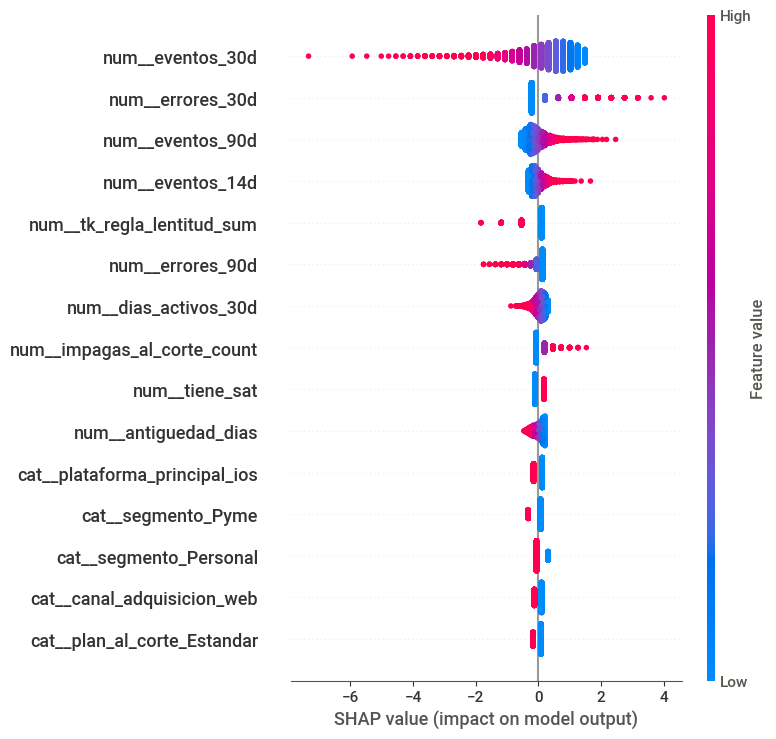

In [35]:
import shap

modelo_final = modelos["01_logreg_simple"]
modelo_final.fit(X, y)

# Extraer datos transformados según los nombres de pasos existentes
pasos = modelo_final.named_steps
X_paso = pasos["ind_sat"].transform(X) if "ind_sat" in pasos else X
prep_step = pasos["prep"]
clf_step = pasos["clf"] if "clf" in pasos else pasos["model"]

X_trans = prep_step.transform(X_paso)
if hasattr(X_trans, "toarray"):
  X_trans = X_trans.toarray()

feature_names = prep_step.get_feature_names_out()

explainer = shap.LinearExplainer(clf_step, X_trans)
shap_values = explainer.shap_values(X_trans)

df_shap_imp = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": np.abs(shap_values).mean(axis=0),
    "coef_estandarizado": clf_step.coef_[0],
}).sort_values("mean_abs_shap", ascending=False)

display(df_shap_imp.head(15))

# Revisar específicamente el aporte de las variables NLP
df_shap_nlp = df_shap_imp[
    df_shap_imp["feature"].str.contains("tk_regla|tk_svd", regex=True)
]
display(df_shap_nlp)

shap.summary_plot(
    shap_values, X_trans, feature_names=feature_names, max_display=15
)

## Atipicos

In [36]:
import numpy as np
import pandas as pd


def cerrar_causas_raiz(
    df_model_train: pd.DataFrame,
    df_eventos: pd.DataFrame,
    df_facturas: pd.DataFrame,
    df_cliente: pd.DataFrame,
    df_suscripciones: pd.DataFrame,
):
  m = df_model_train.copy()
  ev = df_eventos.copy()
  fac = df_facturas.copy()
  cli = df_cliente.copy()
  sus = df_suscripciones.copy()

  col_ver = "version_app" if "version_app" in ev.columns else "version"
  tiene_corte_ev = "fecha_corte" in ev.columns and "fecha_corte" in m.columns
  tiene_corte_m = "fecha_corte" in m.columns

  # Normalizar fechas si existen
  if tiene_corte_m:
    m["fecha_corte_dt"] = pd.to_datetime(m["fecha_corte"], errors="coerce")
  if "fecha_evento" in ev.columns:
    ev["fecha_ev_dt"] = pd.to_datetime(ev["fecha_evento"], errors="coerce")
  elif "timestamp" in ev.columns:
    ev["fecha_ev_dt"] = pd.to_datetime(ev["timestamp"], errors="coerce")
  else:
    ev["fecha_ev_dt"] = pd.NaT

  ev["es_error"] = (
      ev["codigo_error"].notna().astype(int)
      if "codigo_error" in ev.columns
      else 0
  )

  # 1. Plataforma/versión dominante por cliente_id (y fecha_corte si aplica)
  grp_cols = ["cliente_id", "fecha_corte"] if tiene_corte_ev else ["cliente_id"]
  modo_ver = (
      ev.groupby(grp_cols + ["plataforma", col_ver], dropna=False)
      .size()
      .reset_index(name="n_ev")
      .sort_values(
          grp_cols + ["n_ev"], ascending=[True] * len(grp_cols) + [False]
      )
      .drop_duplicates(grp_cols)
  )
  m_ver = m.merge(modo_ver, on=grp_cols, how="left")

  print(
      "\n=== 1A. Churn_90d por plataforma y versión (muro temporal respetado) ==="
  )
  t1a = (
      m_ver.groupby(["plataforma", col_ver], dropna=False)
      .agg(
          n_filas=("churn_90d", "count"),
          clientes_unicos=("cliente_id", "nunique"),
          tasa_churn_90d=("churn_90d", "mean"),
      )
      .query("n_filas >= 30")
      .sort_values("tasa_churn_90d", ascending=False)
      .round(4)
  )
  print(t1a.reset_index().head(10).to_string(index=False))

  if tiene_corte_m:
    print(
        "\n=== 1B. Android 5.4.0 vs 5.3.3 por fecha_corte (maduración de"
        " ventana) ==="
    )
    sub_android = m_ver[
        (m_ver["plataforma"].astype(str).str.lower() == "android")
        & (m_ver[col_ver].astype(str).isin(["5.3.3", "5.4.0"]))
    ]
    t1b = (
        sub_android.groupby(["fecha_corte", col_ver], dropna=False)
        .agg(
            n_filas=("churn_90d", "count"),
            tasa_churn_90d=("churn_90d", "mean"),
        )
        .round(4)
    )
    print(t1b.reset_index().head(10).to_string(index=False))

  # 2. Cruce de motivo_cancelacion contra churn_90d y plataforma/versión
  if "motivo_cancelacion" in sus.columns:
    sus_map = (
        sus.sort_values("cliente_id")
        .drop_duplicates("cliente_id")
        .assign(
            motivo_limpio=lambda d: d["motivo_cancelacion"].fillna(
                "sin_cancelacion_o_None"
            ),
            es_cambio_plan=lambda d: (
                d["motivo_limpio"] == "cambio_plan"
            ).astype(int),
            es_baja_voluntaria_friccion=lambda d: d["motivo_limpio"]
            .isin([
                "problemas_tecnicos",
                "calidad_servicio",
                "facturacion",
                "competencia",
                "precio",
                "no_lo_usa",
            ])
            .astype(int),
        )
    )
    m_mot = m_ver.merge(
        sus_map[[
            "cliente_id",
            "motivo_limpio",
            "es_cambio_plan",
            "es_baja_voluntaria_friccion",
        ]],
        on="cliente_id",
        how="left",
    )
    m_mot["motivo_limpio"] = m_mot["motivo_limpio"].fillna(
        "sin_registro_suscripcion"
    )

    print("\n=== 2A. Churn_90d por motivo_cancelacion ===")
    t2a = (
        m_mot.groupby("motivo_limpio", dropna=False)
        .agg(
            n_filas=("churn_90d", "count"),
            tasa_churn_90d=("churn_90d", "mean"),
        )
        .sort_values("n_filas", ascending=False)
        .round(4)
    )
    print(t2a.reset_index().head(10).to_string(index=False))

    print(
        "\n=== 2B. Motivos de fricción vs cambio_plan por plataforma/versión ==="
    )
    t2b = (
        m_mot.groupby(["plataforma", col_ver], dropna=False)
        .agg(
            n_filas=("churn_90d", "count"),
            tasa_churn_90d=("churn_90d", "mean"),
            pct_cambio_plan=("es_cambio_plan", "mean"),
            pct_friccion_voluntaria=("es_baja_voluntaria_friccion", "mean"),
        )
        .query("n_filas >= 30")
        .sort_values("tasa_churn_90d", ascending=False)
        .round(4)
    )
    print(t2b.reset_index().head(10).to_string(index=False))

  # 3. Retención reactiva: evitar colisión de columnas si ya existe contactado_por_retencion
  if "contactado_por_retencion" in cli.columns:
    cols_cli = ["cliente_id", "contactado_por_retencion"]
    if "fecha_contacto_retencion" in cli.columns:
      cols_cli.append("fecha_contacto_retencion")
    if "estado_actual" in cli.columns:
      cols_cli.append("estado_actual")

    m_ret = m.drop(
        columns=[
            c
            for c in ["contactado_por_retencion", "fecha_contacto_retencion"]
            if c in m.columns
        ]
    ).merge(cli[cols_cli].drop_duplicates("cliente_id"), on="cliente_id", how="left")

    print(
        "\n=== 3. Churn_90d por contactado_por_retencion (sin colisión de"
        " columnas) ==="
    )
    t3 = (
        m_ret.groupby("contactado_por_retencion", dropna=False)
        .agg(
            n_filas=("churn_90d", "count"),
            clientes_unicos=("cliente_id", "nunique"),
            tasa_churn_90d=("churn_90d", "mean"),
        )
        .round(4)
    )
    print(t3.reset_index().head(10).to_string(index=False))

  # 4. Impagos acumulados vs churn_90d
  if "fecha_pago" in fac.columns and "cliente_id" in fac.columns:
    fac["impaga"] = fac["fecha_pago"].isna().astype(int)
    fac_cli = (
        fac.groupby("cliente_id", dropna=False)
        .agg(
            facturas_tot=("impaga", "count"),
            facturas_impagas=("impaga", "sum"),
            tasa_impaga_cli=("impaga", "mean"),
        )
        .reset_index()
    )
    m_fac = m.merge(fac_cli, on="cliente_id", how="left")
    m_fac["tiene_impago"] = (m_fac["facturas_impagas"].fillna(0) > 0).astype(
        int
    )

    print("\n=== 4. Churn_90d según presencia de facturas impagas ===")
    t4 = (
        m_fac.groupby("tiene_impago", dropna=False)
        .agg(
            n_filas=("churn_90d", "count"),
            tasa_churn_90d=("churn_90d", "mean"),
        )
        .round(4)
    )
    print(t4.reset_index().head(10).to_string(index=False))


# Ejecución:
cerrar_causas_raiz(
    df_model_train=df_model_train,
    df_eventos=df_eventos,
    df_facturas=df_facturas,
    df_cliente=df_cliente,
    df_suscripciones=df_suscripciones,
)


=== 1A. Churn_90d por plataforma y versión (muro temporal respetado) ===
plataforma version_app  n_filas  clientes_unicos  tasa_churn_90d
   android       5.3.3     2172              904          0.1593
   android       5.4.0      484              274          0.1136
       ios       5.3.3     1784              794          0.1043
       web         web      435              193          0.0897

=== 1B. Android 5.4.0 vs 5.3.3 por fecha_corte (maduración de ventana) ===
fecha_corte version_app  n_filas  tasa_churn_90d
 2025-03-31       5.3.3      731          0.1218
 2025-03-31       5.4.0       69          0.0000
 2025-06-30       5.3.3      756          0.1614
 2025-06-30       5.4.0      142          0.0070
 2025-09-30       5.3.3      685          0.1971
 2025-09-30       5.4.0      273          0.1978

=== 2A. Churn_90d por motivo_cancelacion ===
         motivo_limpio  n_filas  tasa_churn_90d
sin_cancelacion_o_None     3130          0.0000
           cambio_plan      781         

# Punto 2

In [37]:
DATA_DIR = "/content/drive/MyDrive/NTT/datos"
output_path = os.path.join(DATA_DIR, "predicciones.csv")

precios_plan = {
    "Basico": 23900.0,
    "Estandar": 34900.0,
    "Premium": 49900.0,
    "Familiar": 59900.0,
}

costo_contacto = 25000.0
tasa_exito = 0.40
meses_valor = 12

# 1. Probabilidades del modelo seleccionado (01_logreg_simple)
probs_score = np.clip(modelo_final.predict_proba(X_score)[:, 1], 0.0, 1.0)

# 2. Mensualidad vigente por cliente (ajusta 'plan_vigente' al nombre de tu columna en score_df)
mensualidad = score_df["plan_al_corte"].map(precios_plan).fillna(23900.0).values
valor_12m = mensualidad * meses_valor

# 3. Beneficio esperado y decisión binaria (1 si > 0, 0 en caso contrario)
beneficio_esperado = (probs_score * tasa_exito * valor_12m) - costo_contacto
contactar_dec = (beneficio_esperado > 0).astype(int)

df_pred = pd.DataFrame({
    "cliente_id": score_df["cliente_id"].astype(int),
    "probabilidad": probs_score.astype(float),
    "contactar": contactar_dec,
})

df_pred.to_csv(output_path, index=False)
df_pred.to_csv("predicciones.csv", index=False)

print(f"Total clientes puntuados: {len(df_pred)}")
print(f"A contactar (contactar=1): {df_pred['contactar'].sum()} ({df_pred['contactar'].mean()*100:.2f}%)")
print(f"Beneficio esperado total de la campaña: {beneficio_esperado[contactar_dec == 1].sum():,.0f} COP")

Total clientes puntuados: 1611
A contactar (contactar=1): 416 (25.82%)
Beneficio esperado total de la campaña: 8,695,294 COP


In [38]:
# 1. Tasa de churn_90d por fecha de corte
print("=== Churn_90d por fecha_corte ===")
display(
    df_model_train.groupby("fecha_corte", dropna=False)
    .agg(
        n_filas=("churn_90d", "count"),
        tasa_churn_90d=("churn_90d", "mean"),
    )
    .sort_index()
    .round(4)
)

# 2. Motivo de cancelación cruzado con estado_actual (y churn_90d si existe suscripcion_id)
if "suscripcion_id" in df_suscripciones.columns and "suscripcion_id" in df_model_train.columns:
    df_mot_churn = df_suscripciones.merge(
        df_model_train[["suscripcion_id", "churn_90d"]].drop_duplicates(),
        on="suscripcion_id",
        how="left",
    )
    print("\n=== Motivo de cancelación vs churn_90d ===")
    display(
        df_mot_churn.groupby("motivo_cancelacion", dropna=False)
        .agg(
            n_suscripciones=("motivo_cancelacion", "count"),
            n_con_etiqueta=("churn_90d", "count"),
            tasa_churn_90d=("churn_90d", "mean"),
        )
        .sort_values("n_suscripciones", ascending=False)
        .round(4)
    )

=== Churn_90d por fecha_corte ===


,n_filas,tasa_churn_90d
fecha_corte,,
2025-03-31,1436,0.1072
2025-06-30,1648,0.1268
2025-09-30,1795,0.1487


In [39]:
# Resumen ejecutivo de cifras clave para el Punto 2 (¿Por qué se están yendo?)

# 1. Evolución trimestral de churn_90d
resumen_cortes = (
    df_model_train.groupby("fecha_corte", dropna=False)
    .agg(n_filas=("churn_90d", "count"), tasa_churn_90d=("churn_90d", "mean"))
    .sort_index()
)
print("=== 1. Churn_90d por fecha_corte ===")
for idx, row in resumen_cortes.iterrows():
    print(f"  {idx}: n={int(row['n_filas']):,} | churn_90d={row['tasa_churn_90d']*100:.2f}%")

# 2. Señales clave del modelo (SHAP / coeficientes) y NLP
senales_modelo = {
    "num__eventos_30d": {"shap": 0.784651, "coef": -0.973075},
    "num__errores_30d": {"shap": 0.343158, "coef": 0.546673},
    "num__impagas_al_corte_count": {"shap": None, "coef": 0.204382},
    "num__tk_regla_lentitud_sum": {"shap": 0.180409, "coef": None},
    "num__dias_activos_30d": {"shap": None, "coef": -0.178757},
    "num__antiguedad_dias": {"shap": None, "coef": -0.158186},
    "tk_regla_cancelar_sum": {"shap": None, "coef": 0.151350},
}
print("\n=== 2. Variables y señales NLP clave ===")
for var, vals in senales_modelo.items():
    partes = []
    if vals["shap"] is not None:
        partes.append(f"SHAP={vals['shap']:.6f}")
    if vals["coef"] is not None:
        partes.append(f"coef={vals['coef']:+.6f}")
    print(f"  {var}: " + ", ".join(partes))

# 3. Tasas de error y churn_90d por plataforma/versión
if "df_eventos" in locals() and {"plataforma", "version_app"}.issubset(df_eventos.columns):
    col_err = "es_error" if "es_error" in df_eventos.columns else None
    if col_err:
        err_plat = (
            df_eventos.groupby(["plataforma", "version_app"], dropna=False)
            .agg(
                total_eventos=("cliente_id", "count"),
                tasa_error=(col_err, "mean"),
                clientes_unicos=("cliente_id", "nunique"),
            )
            .sort_values("tasa_error", ascending=False)
        )
        print("\n=== 3a. Tasa de error por plataforma y versión ===")
        display(err_plat.round(4))

if {"plataforma", "version_app", "churn_90d"}.issubset(df_model_train.columns):
    churn_plat = (
        df_model_train.groupby(["plataforma", "version_app"], dropna=False)
        .agg(n=("churn_90d", "count"), tasa_churn_90d=("churn_90d", "mean"))
        .query("n >= 30")
        .sort_values("tasa_churn_90d", ascending=False)
    )
    print("\n=== 3b. Churn_90d por plataforma y versión (n >= 30) ===")
    display(churn_plat.round(4))

# 4. Retención reactiva y motivos de cancelación
if "contactado_por_retencion" in df_model_train.columns:
    ret_res = (
        df_model_train.groupby("contactado_por_retencion", dropna=False)
        .agg(n_filas=("churn_90d", "count"), tasa_churn_90d=("churn_90d", "mean"))
    )
    print("\n=== 4a. Churn_90d según contactado_por_retencion ===")
    display(ret_res.round(4))

if "motivo_cancelacion" in df_suscripciones.columns:
    mot_res = (
        df_suscripciones["motivo_cancelacion"]
        .fillna("sin_cancelacion_o_None")
        .value_counts(dropna=False)
        .to_frame("n")
    )
    mot_res["pct"] = (mot_res["n"] / len(df_suscripciones) * 100).round(2)
    print("\n=== 4b. Distribución de motivo_cancelacion ===")
    display(mot_res)

=== 1. Churn_90d por fecha_corte ===
  2025-03-31 00:00:00: n=1,436 | churn_90d=10.72%
  2025-06-30 00:00:00: n=1,648 | churn_90d=12.68%
  2025-09-30 00:00:00: n=1,795 | churn_90d=14.87%

=== 2. Variables y señales NLP clave ===
  num__eventos_30d: SHAP=0.784651, coef=-0.973075
  num__errores_30d: SHAP=0.343158, coef=+0.546673
  num__impagas_al_corte_count: coef=+0.204382
  num__tk_regla_lentitud_sum: SHAP=0.180409
  num__dias_activos_30d: coef=-0.178757
  num__antiguedad_dias: coef=-0.158186
  tk_regla_cancelar_sum: coef=+0.151350

=== 4b. Distribución de motivo_cancelacion ===


,n,pct
motivo_cancelacion,,
sin_cancelacion_o_None,1611,47.83
cambio_plan,368,10.93
problemas_tecnicos,280,8.31
calidad_servicio,229,6.80
otro,204,6.06
no_lo_usa,188,5.58
facturacion,181,5.37
competencia,170,5.05
precio,137,4.07


In [40]:
# 1. Tasa de error por plataforma y versión (desde df_eventos)
# Si existe columna de fecha en df_eventos y fecha_corte en df_model_train,
# filtra eventos <= fecha_corte antes de calcular métricas por corte.
col_err = "es_error" if "es_error" in df_eventos.columns else None
if col_err:
    print("=== Top versiones/plataformas por tasa de error ===")
    display(
        df_eventos.groupby(["plataforma", "version_app"], dropna=False)
        .agg(
            total_eventos=("cliente_id", "count"),
            tasa_error=(col_err, "mean"),
            clientes_unicos=("cliente_id", "nunique"),
        )
        .sort_values("tasa_error", ascending=False)
        .round(4)
    )

# 2. Churn_90d por plataforma/versión y maduración por fecha_corte
if {"plataforma", "version_app", "churn_90d"}.issubset(df_model_train.columns):
    print("\n=== Churn_90d por plataforma y versión (mín. 30 filas) ===")
    display(
        df_model_train.groupby(["plataforma", "version_app"], dropna=False)
        .agg(
            n=("churn_90d", "count"),
            clientes_unicos=("cliente_id", "nunique"),
            tasa_churn_90d=("churn_90d", "mean"),
        )
        .query("n >= 30")
        .sort_values("tasa_churn_90d", ascending=False)
        .round(4)
    )

    print("\n=== Android 5.4.0 vs 5.3.3 por fecha_corte ===")
    display(
        df_model_train[df_model_train["version_app"].isin(["5.3.3", "5.4.0"])]
        .groupby(["fecha_corte", "version_app"], dropna=False)
        .agg(n_filas=("churn_90d", "count"), tasa_churn_90d=("churn_90d", "mean"))
        .sort_index()
        .round(4)
    )

# 3. Facturación por método de pago (desde df_facturas)
if {"metodo_pago", "monto"}.issubset(df_facturas.columns):
    col_imp = "impaga" if "impaga" in df_facturas.columns else None
    agg_dict = {
        "total_facturas": ("monto", "count"),
        "monto_promedio": ("monto", "mean"),
    }
    if col_imp:
        agg_dict["tasa_impaga"] = (col_imp, "mean")
    print("\n=== Facturas por método de pago ===")
    display(
        df_facturas.groupby("metodo_pago", dropna=False)
        .agg(**agg_dict)
        .round(4)
    )

# 4. Retención y motivos de cancelación
if "contactado_por_retencion" in df_model_train.columns:
    print("\n=== Churn_90d según contactado_por_retencion ===")
    display(
        df_model_train.groupby("contactado_por_retencion", dropna=False)
        .agg(
            n_filas=("churn_90d", "count"),
            clientes_unicos=("cliente_id", "nunique"),
            tasa_churn_90d=("churn_90d", "mean"),
        )
        .round(4)
    )

if "motivo_cancelacion" in df_suscripciones.columns:
    print("\n=== Distribución de motivo_cancelacion ===")
    dist_mot = (
        df_suscripciones["motivo_cancelacion"]
        .fillna("sin_cancelacion_o_None")
        .value_counts(dropna=False)
        .to_frame("n")
    )
    dist_mot["pct"] = (dist_mot["n"] / len(df_suscripciones) * 100).round(2)
    display(dist_mot)


=== Facturas por método de pago ===


,total_facturas,monto_promedio
metodo_pago,,
debito_auto,7025,37354.5196
efectivo,3437,37113.2674
pse,10519,37599.9715
tarjeta,13954,37267.6365



=== Distribución de motivo_cancelacion ===


,n,pct
motivo_cancelacion,,
sin_cancelacion_o_None,1611,47.83
cambio_plan,368,10.93
problemas_tecnicos,280,8.31
calidad_servicio,229,6.80
otro,204,6.06
no_lo_usa,188,5.58
facturacion,181,5.37
competencia,170,5.05
precio,137,4.07


In [41]:
import numpy as np
import pandas as pd

# ==============================================================================
# CELDA DE SOPORTE AJUSTADA — EVIDENCIA PARA "¿POR QUÉ SE ESTÁN YENDO?"
# ==============================================================================

# 1. Evolución trimestral de churn_90d por fecha_corte
if {"fecha_corte", "churn_90d"}.issubset(df_model_train.columns):
    print("=== 1. Evolución de churn_90d por fecha_corte ===")
    resumen_cortes = (
        df_model_train.groupby("fecha_corte", dropna=False)
        .agg(
            n_filas=("churn_90d", "count"),
            clientes_unicos=("cliente_id", "nunique")
            if "cliente_id" in df_model_train.columns
            else ("churn_90d", "count"),
            tasa_churn_90d=("churn_90d", "mean"),
        )
        .sort_index()
    )
    display(resumen_cortes.round(4))

# 2. Tasa de error por plataforma y versión (desde df_eventos usando 'codigo_error')
if "df_eventos" in locals() and isinstance(df_eventos, pd.DataFrame):
    if {"plataforma", "version_app", "codigo_error"}.issubset(df_eventos.columns):
        df_ev_tmp = df_eventos.copy()
        err_cod = df_ev_tmp["codigo_error"].astype(str).str.strip().str.lower()
        df_ev_tmp["_es_error"] = (
            df_ev_tmp["codigo_error"].notna()
            & (~err_cod.isin(["", "none", "nan", "null", "sin_error", "0"]))
        ).astype(int)

        print("\n=== 2. Tasa de error por plataforma y versión (df_eventos) ===")
        err_plat = (
            df_ev_tmp.groupby(["plataforma", "version_app"], dropna=False)
            .agg(
                total_eventos=("_es_error", "count"),
                tasa_error=("_es_error", "mean"),
                clientes_unicos=("cliente_id", "nunique")
                if "cliente_id" in df_ev_tmp.columns
                else ("_es_error", "count"),
            )
            .sort_values("tasa_error", ascending=False)
        )
        display(err_plat.round(4))

# 3. Churn_90d por plataforma_principal en df_model_train
if {"plataforma_principal", "churn_90d"}.issubset(df_model_train.columns):
    print("\n=== 3. Churn_90d por plataforma_principal (mín. 30 filas) ===")
    churn_plat = (
        df_model_train.groupby("plataforma_principal", dropna=False)
        .agg(
            n_filas=("churn_90d", "count"),
            clientes_unicos=("cliente_id", "nunique")
            if "cliente_id" in df_model_train.columns
            else ("churn_90d", "count"),
            tasa_churn_90d=("churn_90d", "mean"),
        )
        .query("n_filas >= 30")
        .sort_values("tasa_churn_90d", ascending=False)
    )
    display(churn_plat.round(4))

# 4. Facturas impagas por método de pago (df_facturas) y churn_90d vs impagas_al_corte_count
if "df_facturas" in locals() and isinstance(df_facturas, pd.DataFrame):
    col_fpago = "fecha_pago_dt" if "fecha_pago_dt" in df_facturas.columns else "fecha_pago"
    if {"metodo_pago", "monto"}.issubset(df_facturas.columns) and col_fpago in df_facturas.columns:
        df_fac_tmp = df_facturas.copy()
        df_fac_tmp["_es_impaga"] = df_fac_tmp[col_fpago].isna().astype(int)

        print("\n=== 4A. Facturas impagas y monto promedio por método de pago ===")
        fact_met = (
            df_fac_tmp.groupby("metodo_pago", dropna=False)
            .agg(
                total_facturas=("monto", "count"),
                tasa_impaga=("_es_impaga", "mean"),
                monto_promedio=("monto", "mean"),
            )
            .sort_values("tasa_impaga", ascending=False)
        )
        display(fact_met.round(4))

if {"impagas_al_corte_count", "churn_90d"}.issubset(df_model_train.columns):
    df_imp_tmp = df_model_train.copy()
    df_imp_tmp["tiene_impago"] = (df_imp_tmp["impagas_al_corte_count"].fillna(0) > 0).astype(int)
    print("\n=== 4B. Churn_90d según tiene_impago (impagas_al_corte_count > 0) ===")
    display(
        df_imp_tmp.groupby("tiene_impago", dropna=False)
        .agg(
            n_filas=("churn_90d", "count"),
            tasa_churn_90d=("churn_90d", "mean"),
        )
        .round(4)
    )

# 5. Retención reactiva: contactado_retencion_hasta_corte
col_ret = "contactado_retencion_hasta_corte"
if {col_ret, "churn_90d"}.issubset(df_model_train.columns):
    print(f"\n=== 5A. Churn_90d por {col_ret} ===")
    ret_churn = (
        df_model_train.groupby(col_ret, dropna=False)
        .agg(
            n_filas=("churn_90d", "count"),
            clientes_unicos=("cliente_id", "nunique")
            if "cliente_id" in df_model_train.columns
            else ("churn_90d", "count"),
            tasa_churn_90d=("churn_90d", "mean"),
        )
    )
    display(ret_churn.round(4))

    if "estado_actual" in df_model_train.columns and "cliente_id" in df_model_train.columns:
        print(f"\n=== 5B. Clientes únicos por {col_ret} y estado_actual ===")
        ret_estado = (
            df_model_train.drop_duplicates(subset=["cliente_id"])
            .groupby([col_ret, "estado_actual"], dropna=False)["cliente_id"]
            .nunique()
            .rename("n_clientes")
        )
        display(ret_estado)

# 6. Motivos de cancelación: distribución en suscripciones y cruce con churn_90d por cliente_id
if (
    "df_suscripciones" in locals()
    and isinstance(df_suscripciones, pd.DataFrame)
    and "motivo_cancelacion" in df_suscripciones.columns
):
    print("\n=== 6A. Distribución de motivo_cancelacion en suscripciones ===")
    mot_limpio_susc = df_suscripciones["motivo_cancelacion"].fillna("sin_cancelacion_o_None")
    dist_mot = mot_limpio_susc.value_counts(dropna=False).to_frame("n")
    dist_mot["pct"] = (dist_mot["n"] / len(df_suscripciones) * 100).round(2)
    display(dist_mot)

    if {"cliente_id", "churn_90d"}.issubset(df_model_train.columns) and "cliente_id" in df_suscripciones.columns:
        df_susc_mot = df_suscripciones[["cliente_id", "motivo_cancelacion"]].drop_duplicates(subset=["cliente_id"])
        df_mot_cruce = df_model_train.merge(df_susc_mot, on="cliente_id", how="left")
        df_mot_cruce["motivo_limpio"] = df_mot_cruce["motivo_cancelacion"].fillna(
            "sin_cancelacion_o_None"
        )
        print("\n=== 6B. Churn_90d por motivo_limpio (cruce por cliente_id) ===")
        display(
            df_mot_cruce.groupby("motivo_limpio", dropna=False)
            .agg(
                n_filas=("churn_90d", "count"),
                tasa_churn_90d=("churn_90d", "mean"),
            )
            .sort_values("tasa_churn_90d", ascending=False)
            .round(4)
        )

=== 1. Evolución de churn_90d por fecha_corte ===


,n_filas,clientes_unicos,tasa_churn_90d
fecha_corte,,,
2025-03-31,1436,1436,0.1072
2025-06-30,1648,1648,0.1268
2025-09-30,1795,1795,0.1487



=== 2. Tasa de error por plataforma y versión (df_eventos) ===


total_eventos  tasa_error  clientes_unicos
plataforma version_app                                            
android    5.4.0                15820      0.5110              704
           5.3.3                42448      0.0231             1232
ios        5.3.3                39152      0.0210              879
web        web                  10392      0.0198              220


=== 3. Churn_90d por plataforma_principal (mín. 30 filas) ===


,n_filas,clientes_unicos,tasa_churn_90d
plataforma_principal,,,
android,2659,1181,0.1519
ios,1785,795,0.1048
web,435,193,0.0897


... (6 outputs left out)


=== 6A. Distribución de motivo_cancelacion en suscripciones ===


,n,pct
motivo_cancelacion,,
sin_cancelacion_o_None,1611,47.83
cambio_plan,368,10.93
problemas_tecnicos,280,8.31
calidad_servicio,229,6.80
otro,204,6.06
no_lo_usa,188,5.58
facturacion,181,5.37
competencia,170,5.05
precio,137,4.07



=== 6B. Churn_90d por motivo_limpio (cruce por cliente_id) ===


,n_filas,tasa_churn_90d
motivo_limpio,,
facturacion,104,0.6250
competencia,109,0.6239
precio,78,0.6026
calidad_servicio,176,0.5625
no_lo_usa,105,0.5619
problemas_tecnicos,236,0.5339
otro,160,0.5250
cambio_plan,781,0.1050
sin_cancelacion_o_None,3130,0.0000


# Plus

In [42]:
%%writefile app.py
import os
import numpy as np
import pandas as pd
import streamlit as st

st.set_page_config(
    page_title="Punto Plus | Riesgo de Clientes y Retención",
    page_icon="📡",
    layout="wide",
)

st.title("📡 Punto Plus — Radar de Riesgo de Clientes")
st.caption(
    "Visualización del riesgo de fuga, factores principales y priorización "
    "de clientes a contactar."
)


@st.cache_data
def cargar_datos():
    rutas_df = [
        "dashboard_clientes.csv",
        "/content/drive/MyDrive/NTT/datos/dashboard_clientes.csv",
    ]
    rutas_shap = [
        "shap_importancia.csv",
        "/content/drive/MyDrive/NTT/datos/shap_importancia.csv",
    ]

    df_path = next((r for r in rutas_df if os.path.exists(r)), None)
    if df_path is None:
        return None, None

    df = pd.read_csv(df_path)
    shap_path = next((r for r in rutas_shap if os.path.exists(r)), None)
    shap_df = pd.read_csv(shap_path) if shap_path else None
    return df, shap_df


df, shap_df = cargar_datos()

if df is None:
    st.error(
        "No se encontró 'dashboard_clientes.csv'. Verifica la carpeta de trabajo "
        "o '/content/drive/MyDrive/NTT/datos/dashboard_clientes.csv'."
    )
    st.stop()

# --- Barra lateral: Supuestos económicos y filtros ---
st.sidebar.header("⚙️ Simulación Económica")
costo_contacto = st.sidebar.number_input(
    "Costo por contacto (COP)", min_value=0, max_value=500000, value=25000, step=1000
)
tasa_exito = (
    st.sidebar.slider(
        "Tasa de éxito de retención (%)", min_value=5, max_value=100, value=40, step=5
    )
    / 100.0
)
meses_valor = st.sidebar.slider(
    "Horizonte de valor retenido (meses)", min_value=1, max_value=24, value=12, step=1
)

st.sidebar.header("🔍 Filtros")
planes_disp = sorted(df["plan_al_corte"].dropna().unique().tolist()) if "plan_al_corte" in df.columns else []
planes_sel = st.sidebar.multiselect("Plan al corte", planes_disp, default=planes_disp)

plat_disp = sorted(df["plataforma_principal"].dropna().unique().tolist()) if "plataforma_principal" in df.columns else []
plat_sel = st.sidebar.multiselect("Plataforma principal", plat_disp, default=plat_disp)

seg_disp = sorted(df["segmento"].dropna().unique().tolist()) if "segmento" in df.columns else []
seg_sel = st.sidebar.multiselect("Segmento", seg_disp, default=seg_disp)

ciudades_disp = sorted(df["ciudad_clean"].dropna().unique().tolist()) if "ciudad_clean" in df.columns else []
ciudades_sel = st.sidebar.multiselect("Ciudad", ciudades_disp, default=ciudades_disp)

solo_contactar = st.sidebar.checkbox("Mostrar solo clientes a contactar", value=False)

# --- Cálculo dinámico manteniendo columnas base ---
df_calc = df.copy()
if "mensualidad_cop" not in df_calc.columns and "valor_12m_cop" in df_calc.columns:
    df_calc["mensualidad_cop"] = df_calc["valor_12m_cop"] / 12.0

df_calc["valor_horizonte_cop"] = df_calc["mensualidad_cop"] * meses_valor
df_calc["beneficio_simulado_cop"] = (
    df_calc["probabilidad"] * tasa_exito * df_calc["valor_horizonte_cop"]
) - costo_contacto
df_calc["contactar_simulado"] = (df_calc["beneficio_simulado_cop"] > 0).astype(int)

mask = pd.Series(True, index=df_calc.index)
if planes_sel and "plan_al_corte" in df_calc.columns:
    mask &= df_calc["plan_al_corte"].isin(planes_sel)
if plat_sel and "plataforma_principal" in df_calc.columns:
    mask &= df_calc["plataforma_principal"].isin(plat_sel)
if seg_sel and "segmento" in df_calc.columns:
    mask &= df_calc["segmento"].isin(seg_sel)
if ciudades_sel and "ciudad_clean" in df_calc.columns:
    mask &= df_calc["ciudad_clean"].isin(ciudades_sel)
if solo_contactar:
    mask &= df_calc["contactar_simulado"] == 1

df_view = (
    df_calc.loc[mask]
    .sort_values(["contactar_simulado", "beneficio_simulado_cop", "probabilidad"], ascending=False)
    .copy()
)
df_contact = df_view[df_view["contactar_simulado"] == 1]

# --- KPIs Principales ---
k1, k2, k3, k4 = st.columns(4)
k1.metric("Clientes evaluados", f"{len(df_view):,}")
k2.metric(
    "A contactar",
    f"{len(df_contact):,}",
    f"{(len(df_contact) / max(len(df_view), 1)) * 100:.1f}% del segmento",
)
k3.metric("Riesgo promedio", f"{df_view['probabilidad'].mean() * 100:.2f}%")
k4.metric(
    "Beneficio esperado neto (COP)",
    f"${df_contact['beneficio_simulado_cop'].sum():,.0f}",
)

st.divider()

# --- Pestañas ---
tab1, tab2, tab3 = st.tabs([
    "📋 Lista de Clientes a Contactar",
    "📊 Riesgo por Segmento, Plan y Ciudad",
    "🧠 Factores Principales",
])

with tab1:
    st.subheader("Lista priorizada de clientes a contactar")
    cols_orden = [
        "cliente_id",
        "probabilidad",
        "contactar_simulado",
        "contactar",
        "segmento",
        "ciudad_clean",
        "plataforma_principal",
        "plan_al_corte",
        "antiguedad_dias",
        "eventos_30d",
        "errores_30d",
        "impagas_al_corte_count",
        "tickets_abiertos_al_corte",
        "sat_promedio",
        "mensualidad_cop",
        "valor_12m_cop",
        "beneficio_esperado_cop",
        "beneficio_simulado_cop",
    ]
    cols_presentes = [c for c in cols_orden if c in df_view.columns]

    df_tabla = df_view[cols_presentes].copy()
    df_tabla["probabilidad"] = (df_tabla["probabilidad"] * 100).round(2)
    df_tabla = df_tabla.rename(columns={
        "cliente_id": "ID Cliente",
        "probabilidad": "Riesgo (%)",
        "contactar_simulado": "Contactar (Sim.)",
        "contactar": "Contactar (Base)",
        "segmento": "Segmento",
        "ciudad_clean": "Ciudad",
        "plataforma_principal": "Plataforma",
        "plan_al_corte": "Plan",
        "antiguedad_dias": "Antigüedad (días)",
        "eventos_30d": "Eventos 30d",
        "errores_30d": "Errores 30d",
        "impagas_al_corte_count": "Facturas Impagas",
        "tickets_abiertos_al_corte": "Tickets Abiertos",
        "sat_promedio": "SAT Promedio",
        "mensualidad_cop": "Mensualidad (COP)",
        "valor_12m_cop": "Valor 12m (COP)",
        "beneficio_esperado_cop": "Beneficio Base (COP)",
        "beneficio_simulado_cop": "Beneficio Sim. (COP)",
    })

    st.dataframe(df_tabla, use_container_width=True, height=430)

    cols_descarga = [
        c for c in [
            "cliente_id", "probabilidad", "contactar_simulado", "contactar",
            "plan_al_corte", "plataforma_principal", "beneficio_simulado_cop"
        ] if c in df_view.columns
    ]
    csv_bytes = df_view[cols_descarga].to_csv(index=False).encode("utf-8")
    st.download_button(
        label="⬇️ Descargar lista a contactar (CSV)",
        data=csv_bytes,
        file_name="clientes_a_contactar_punto_plus.csv",
        mime="text/csv",
    )

with tab2:
    c1, c2 = st.columns(2)
    with c1:
        st.subheader("Riesgo y contactos por Plan")
        if "plan_al_corte" in df_view.columns:
            res_plan = df_view.groupby("plan_al_corte", as_index=False).agg(
                clientes=("cliente_id", "count"),
                a_contactar=("contactar_simulado", "sum"),
                riesgo_pct=("probabilidad", lambda s: round(s.mean() * 100, 2)),
            )
            st.dataframe(res_plan, use_container_width=True)
            st.bar_chart(res_plan.set_index("plan_al_corte")["riesgo_pct"])

    with c2:
        st.subheader("Riesgo y contactos por Plataforma")
        if "plataforma_principal" in df_view.columns:
            res_plat = df_view.groupby("plataforma_principal", as_index=False).agg(
                clientes=("cliente_id", "count"),
                a_contactar=("contactar_simulado", "sum"),
                riesgo_pct=("probabilidad", lambda s: round(s.mean() * 100, 2)),
            )
            st.dataframe(res_plat, use_container_width=True)
            st.bar_chart(res_plat.set_index("plataforma_principal")["a_contactar"])

    if "ciudad_clean" in df_view.columns:
        st.subheader("Riesgo promedio por Ciudad")
        res_ciudad = (
            df_view.groupby("ciudad_clean", as_index=False)
            .agg(
                clientes=("cliente_id", "count"),
                a_contactar=("contactar_simulado", "sum"),
                riesgo_pct=("probabilidad", lambda s: round(s.mean() * 100, 2)),
            )
            .sort_values("riesgo_pct", ascending=False)
        )
        st.dataframe(res_ciudad, use_container_width=True)

with tab3:
    st.subheader("Factores principales del modelo")
    if shap_df is not None and not shap_df.empty:
        top_shap = shap_df.head(12).copy()
        if "coef_estandarizado" in top_shap.columns:
            top_shap["Dirección"] = np.where(
                top_shap["coef_estandarizado"] > 0,
                "⬆️ Aumenta riesgo",
                "⬇️ Reduce riesgo",
            )
        st.dataframe(top_shap, use_container_width=True)
        if "feature" in top_shap.columns and "mean_abs_shap" in top_shap.columns:
            st.bar_chart(top_shap.set_index("feature")["mean_abs_shap"])
    else:
        st.info("No se encontró 'shap_importancia.csv'; mostrando señales operativas disponibles en el dataset.")

    # Señales operativas de los clientes en vista (errores, impagas, tickets, SAT)
    cols_senales = [
        c for c in ["errores_30d", "impagas_al_corte_count", "tickets_abiertos_al_corte", "sat_promedio", "eventos_30d"]
        if c in df_view.columns
    ]
    if cols_senales:
        st.markdown("### Promedios operativos en el segmento filtrado")
        st.dataframe(
            df_view[cols_senales].mean().round(2).to_frame(name="Promedio"),
            use_container_width=True,
        )

Writing app.py


In [43]:
import os
from google.colab import drive

if not os.path.exists("/content/drive/MyDrive"):
  drive.mount("/content/drive")

%cd "/content/drive/MyDrive/NTT/datos"
!mv /content/app.py /content/drive/MyDrive/NTT/datos/app.py
!ls -lh /content/drive/MyDrive/NTT/datos/app.py

/content/drive/MyDrive/NTT/datos
-rw------- 1 root root 9.4K Nov 21 02:19 /content/drive/MyDrive/NTT/datos/app.py


In [44]:
import os
import time
from google.colab import drive

!pip install -q streamlit pycloudflared

from pycloudflared import try_cloudflare

if not os.path.exists("/content/drive/MyDrive"):
  drive.mount("/content/drive")

app_path = "/content/drive/MyDrive/NTT/datos/app.py"

!pkill -f streamlit || true
!pkill -f cloudflared || true
!streamlit run "{app_path}" --server.port 8501 --server.address 0.0.0.0 --server.headless true &>/content/logs.txt &

time.sleep(5)
!cat /content/logs.txt
print(try_cloudflare(port=8501))

^C
^C


2026-11-21 02:19:43.799 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://104.197.181.84:8501

 * Running on https://visible-discipline-marking-roland.trycloudflare.com
 * Traffic stats available on http://127.0.0.1:20241/metrics
Urls(tunnel='https://visible-discipline-marking-roland.trycloudflare.com', metrics='http://127.0.0.1:20241/metrics', process=<Popen: returncode: None args: ['/usr/local/lib/python3.13/dist-packages/pyc...>)
